<div dir="rtl" style="text-align: right">

# مدل اولیه‌ی پیش‌بینی نکول در اعتبارسنجی مشتریان

هدف این نوت‌بوک، آماده‌سازی و تحلیل اولیه‌ی دیتاست German Credit و بررسی یک مدل پشتیبان تصمیم برای برآورد احتمال نکول متقاضیان وام است.

در این نوت‌بوک، `default=1` به معنی نکول و `default=0` به معنی خوش‌حسابی است. داده شامل ۱۰۰۰ پرونده‌ی تاریخی است و فقط وام‌های پذیرفته‌شده را در بر می‌گیرد؛ بنابراین نتایج ممکن است تحت تأثیر سوگیری انتخاب باشند و رابطه‌ی آماری را نباید رابطه‌ی علّی تفسیر کرد.

این تحلیل آموزشی و اولیه است و به‌تنهایی مبنای تصمیم‌گیری خودکار یا استقرار مدل نیست.

</div>

<div dir="rtl" style="text-align: right">

## کتابخانه‌ها و تنظیمات

</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
import os
os.makedirs("figures", exist_ok=True)

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             confusion_matrix, roc_curve, precision_recall_curve)
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier
import shap
from lime.lime_tabular import LimeTabularExplainer

SEED = 42                      # برای تکرارپذیری (Reproducibility)
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110


<div dir="rtl" style="text-align: right">

## بارگذاری داده و تعریف ستون‌ها

</div>

In [2]:
data = pd.read_csv("german.data", sep=r"\s+", header=None)
 # فایل خام باید کنار نوت‌ بوک باشد

In [3]:
df = data.copy()

In [4]:
columns = ["checking",
 "duration",
  "credit_history",
   "purpose",
    "credit_amount",
     "savings",
           "employment",
            "installment_rate",
             "personal_status",
              "other_debtors",
               "residence_since",
           "property",
            "age",
             "other_plans",
              "housing",
               "existing_credits",
                "job",
                 "dependents",
           "telephone",
            "foreign_worker",
             "target_raw"]
             # نام ستون‌ها دقیقاً بر اساس german.doc (۲۰ ویژگی + برچسب)
df.columns = columns

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   checking          1000 non-null   object
 1   duration          1000 non-null   int64 
 2   credit_history    1000 non-null   object
 3   purpose           1000 non-null   object
 4   credit_amount     1000 non-null   int64 
 5   savings           1000 non-null   object
 6   employment        1000 non-null   object
 7   installment_rate  1000 non-null   int64 
 8   personal_status   1000 non-null   object
 9   other_debtors     1000 non-null   object
 10  residence_since   1000 non-null   int64 
 11  property          1000 non-null   object
 12  age               1000 non-null   int64 
 13  other_plans       1000 non-null   object
 14  housing           1000 non-null   object
 15  existing_credits  1000 non-null   int64 
 16  job               1000 non-null   object
 17  dependents     

<div dir="rtl" style="text-align: right">

## تعریف متغیر هدف و مقادیر دسته‌ای

برچسب اصلی دیتاست به متغیر `default` تبدیل می‌شود: مقدار ۱ نشان‌دهنده‌ی نکول و مقدار ۰ نشان‌دهنده‌ی خوش‌حسابی است. کدهای دسته‌ای نیز برای خوانایی بیشتر به برچسب‌های متنی تبدیل می‌شوند.

پس از نام گذاری، کنترل می‌کنیم که هیچ کد ناشناخته‌ای به مقدار گمشده تبدیل نشده باشد.

</div>

In [6]:
# تبدیل برچسب:  استاندارد پروژه: 0 = (برچسب اصلی 1)خوش‌حساب و 1 = (برچسب اصلی 2)نکول
df["default"] = (df["target_raw"] == 2).astype(int)
df = df.drop(columns="target_raw")

In [7]:
code_map = {
 "checking":       {"A11":"lt_0DM","A12":"0_200DM","A13":"ge_200DM","A14":"no_account"},
 "credit_history": {"A30":"no_credits_all_paid","A31":"all_paid_this_bank","A32":"existing_paid_duly",
                    "A33":"past_delay","A34":"critical_other_credits"},
 "purpose":        {"A40":"car_new","A41":"car_used","A42":"furniture","A43":"radio_tv","A44":"appliances",
                    "A45":"repairs","A46":"education","A47":"vacation","A48":"retraining","A49":"business","A410":"other"},
 "savings":        {"A61":"lt_100","A62":"100_500","A63":"500_1000","A64":"ge_1000","A65":"unknown_none"},
 "employment":     {"A71":"unemployed","A72":"lt_1y","A73":"1_4y","A74":"4_7y","A75":"ge_7y"},
 "personal_status":{"A91":"male_div_sep","A92":"female_div_sep_mar","A93":"male_single","A94":"male_mar_wid","A95":"female_single"},
 "other_debtors":  {"A101":"none","A102":"co_applicant","A103":"guarantor"},
 "property":       {"A121":"real_estate","A122":"savings_insurance","A123":"car_other","A124":"unknown_none"},
 "other_plans":    {"A141":"bank","A142":"stores","A143":"none"},
 "housing":        {"A151":"rent","A152":"own","A153":"free"},
 "job":            {"A171":"unemployed_unskilled_nonres","A172":"unskilled_res","A173":"skilled","A174":"management_highly_qualified"},
 "telephone":      {"A191":"none","A192":"yes"},
 "foreign_worker": {"A201":"yes","A202":"no"},
}


In [8]:
for col in code_map:
    print(f"{col}: {df[col].unique()}")
    

checking: ['A11' 'A12' 'A14' 'A13']
credit_history: ['A34' 'A32' 'A33' 'A30' 'A31']
purpose: ['A43' 'A46' 'A42' 'A40' 'A41' 'A49' 'A44' 'A45' 'A410' 'A48']
savings: ['A65' 'A61' 'A63' 'A64' 'A62']
employment: ['A75' 'A73' 'A74' 'A71' 'A72']
personal_status: ['A93' 'A92' 'A91' 'A94']
other_debtors: ['A101' 'A103' 'A102']
property: ['A121' 'A122' 'A124' 'A123']
other_plans: ['A143' 'A141' 'A142']
housing: ['A152' 'A153' 'A151']
job: ['A173' 'A172' 'A174' 'A171']
telephone: ['A192' 'A191']
foreign_worker: ['A201' 'A202']


<div dir="rtl" style="text-align: right">

در داده‌ی حاضر چهار سطح از `personal_status` مشاهده شده است. سطح `female_single` در نمونه‌های موجود دیده نمی‌شود.  باید هنگام ساخت مدل، رفتار پیش‌پردازش در برابر سطح‌های دسته‌ایِ دیده‌نشده در داده‌ی آموزش بررسی شود.

</div>

In [9]:
df["personal_status"].value_counts()

personal_status
A93    548
A92    310
A94     92
A91     50
Name: count, dtype: int64

In [10]:
for col, mapping in code_map.items():
    df[col] = df[col].map(mapping)
assert df.isna().sum().sum() == 0, "یک کد ناشناخته در نگاشت وجود دارد"

<div dir="rtl" style="text-align: right">

## کنترل کیفیت و خلاصه‌ی داده

در این بخش تعداد نمونه‌ها و ویژگی‌ها، نوع ستون‌ها، مقادیر گمشده، ردیف‌های تکراری و توزیع برچسب هدف بررسی می‌شود. دسته‌هایی مانند `unknown_none` در فایل به‌صورت سطح‌های دسته‌ای ثبت شده‌اند و با مقدار گمشده‌ی واقعی (`NaN`) یکی نیستند.

</div>

In [11]:
df.head()

,checking,duration,credit_history,purpose,credit_amount,savings,employment,installment_rate,personal_status,other_debtors,...,property,age,other_plans,housing,existing_credits,job,dependents,telephone,foreign_worker,default
0,lt_0DM,6,critical_other_credits,radio_tv,1169,unknown_none,ge_7y,4,male_single,none,...,real_estate,67,none,own,2,skilled,1,yes,yes,0
1,0_200DM,48,existing_paid_duly,radio_tv,5951,lt_100,1_4y,2,female_div_sep_mar,none,...,real_estate,22,none,own,1,skilled,1,none,yes,1
2,no_account,12,critical_other_credits,education,2096,lt_100,4_7y,2,male_single,none,...,real_estate,49,none,own,1,unskilled_res,2,none,yes,0
3,lt_0DM,42,existing_paid_duly,furniture,7882,lt_100,4_7y,2,male_single,guarantor,...,savings_insurance,45,none,free,1,skilled,2,none,yes,0
4,lt_0DM,24,past_delay,car_new,4870,lt_100,1_4y,3,male_single,none,...,unknown_none,53,none,free,2,skilled,2,none,yes,1


In [12]:
import pandas as pd
from IPython.display import display, Markdown

#  مشخص کردن ستون‌های عددی و دسته‌ای

num_cols = [
    "duration",
    "credit_amount",
    "installment_rate",
    "residence_since",
    "age",
    "existing_credits",
    "dependents"
]

cat_cols = df.drop(columns=num_cols + ["default"]).columns.tolist()


summary = pd.DataFrame({
    "شاخص": [
        "تعداد نمونه‌ها",
        "تعداد کل ویژگی‌ها",
        "ویژگی‌های عددی",
        "ویژگی‌های دسته‌ای",
        "مقادیر گمشده",
        "ردیف‌های تکراری"
    ],
    "مقدار": [
        len(df),
        len(num_cols) + len(cat_cols),
        len(num_cols),
        len(cat_cols),
        int(df.isna().sum().sum()),
        int(df.duplicated().sum())
    ]
})

display(summary)





,شاخص,مقدار
0,تعداد نمونه‌ها,1000
1,تعداد کل ویژگی‌ها,20
2,ویژگی‌های عددی,7
3,ویژگی‌های دسته‌ای,13
4,مقادیر گمشده,0
5,ردیف‌های تکراری,0


In [13]:

# 3. بررسی وضعیت خوش‌حسابی و نکول

n_good = (df["default"] == 0).sum()
n_bad = (df["default"] == 1).sum()

#  توزیع متغیر هدف
display(Markdown("##  توزیع وضعیت اعتباری مشتریان"))

target_summary = pd.DataFrame({
    "وضعیت": ["خوش‌حساب", "دارای نکول"],
    "تعداد": [n_good, n_bad],
    "درصد": [
        round(n_good / len(df) * 100, 1),
        round(n_bad / len(df) * 100, 1)
    ]
})
display(target_summary)

##  توزیع وضعیت اعتباری مشتریان

,وضعیت,تعداد,درصد
0,خوش‌حساب,700,70.0
1,دارای نکول,300,30.0


In [14]:
imbalance_ratio = max(n_good, n_bad) / min(n_good, n_bad)

display(Markdown(
    f"**نرخ نکول:** {n_bad / len(df):.1%}  \n"
    f"**(Imbalance_Ratio)نسبت عدم تعادل کلاس‌ها:** {imbalance_ratio:.2f}"
))


**نرخ نکول:** 30.0%  
**(Imbalance_Ratio)نسبت عدم تعادل کلاس‌ها:** 2.33

In [15]:

#  بررسی مقادیر دسته‌ای نامشخص
display(Markdown("##  بررسی دسته‌های نامشخص"))

unknown_summary = pd.DataFrame({
    "ستون": ["savings", "property"],
    "تعداد unknown": [
        (df["savings"] == "unknown_none").sum(),
        (df["property"] == "unknown_none").sum()
    ]
})

unknown_summary["درصد"] = (
    unknown_summary["تعداد unknown"] / len(df) * 100
).round(1)

display(unknown_summary)

##  بررسی دسته‌های نامشخص

,ستون,تعداد unknown,درصد
0,savings,183,18.3
1,property,154,15.4


<div dir="rtl" style="text-align: right">
«مقادیر unknown در ویژگی‌های savings و property به‌عنوان سطوح مستقل دسته‌ای حفظ شده‌اند و با مقادیر گمشده‌ی واقعی (NaN) یکسان نیستند.»
<div>

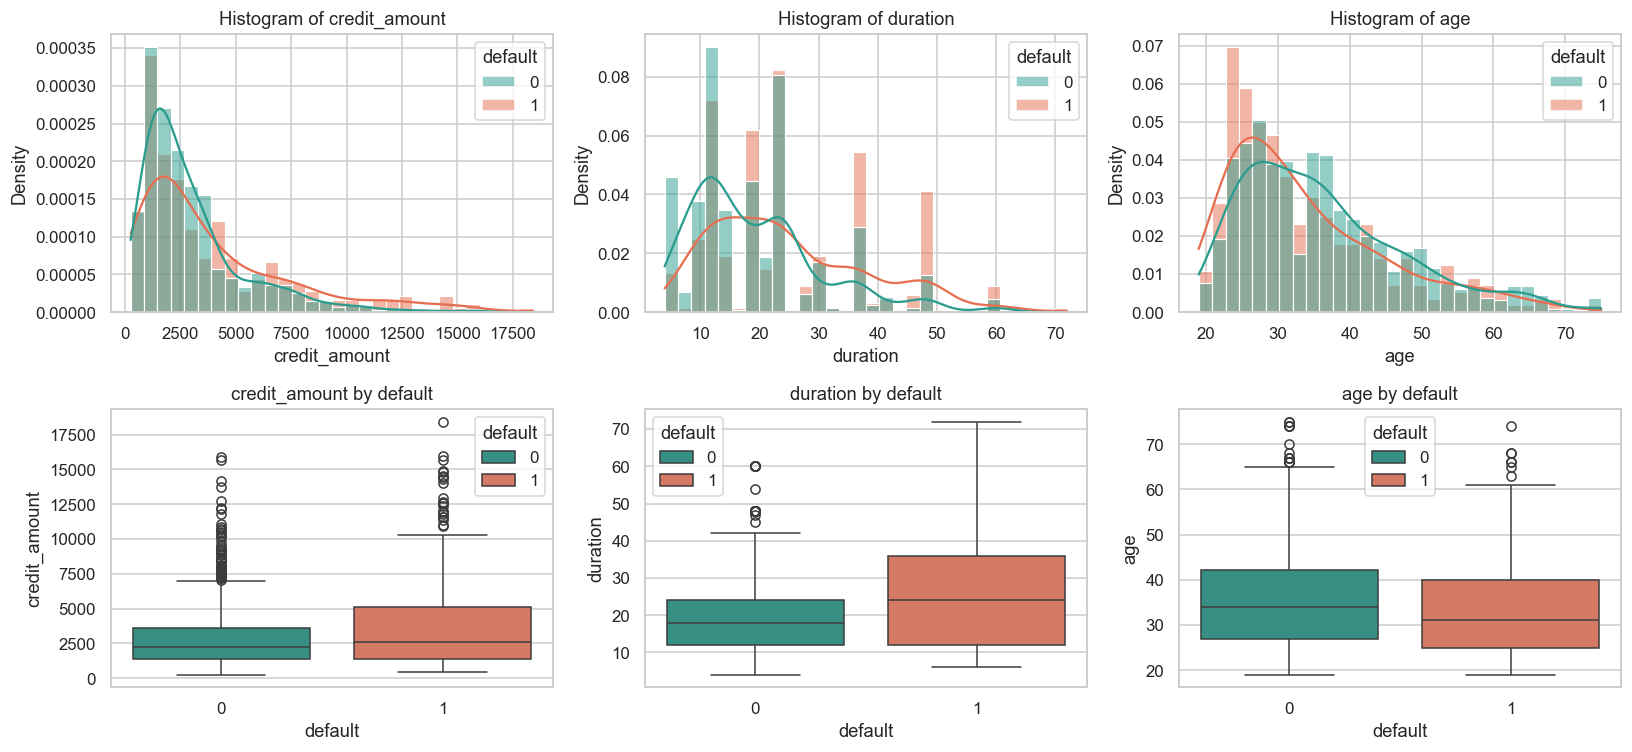

In [16]:
from pathlib import Path
Path("figures").mkdir(parents=True, exist_ok=True)

# ویژگی‌هایی که توزیعشان را بررسی می‌کنیم
key_vars = ["credit_amount", "duration", "age"]

# ساخت شکل: ردیف اول هیستوگرام، ردیف دوم boxplot
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 7))

# رنگ‌های مربوط به دو گروه هدف
palette = {
    0: "#2a9d8f",  # خوش‌حساب
    1: "#e76f51"   # نکول
}

# برای هر ویژگی، یک هیستوگرام و یک boxplot رسم می‌کنیم
for column_index, variable in enumerate(key_vars):

    # توزیع ویژگی به تفکیک وضعیت نکول
    sns.histplot(
        data=df,
        x=variable,
        hue="default",
        bins=30,
        kde=True,
        palette=palette,
        ax=axes[0, column_index],
        stat="density",
        common_norm=False
    )
    axes[0, column_index].set_title(f"Histogram of {variable}")

    # مقایسهٔ مقدار ویژگی برای خوش‌حساب‌ها و افرادی که نکول کرده‌اند
    sns.boxplot(
        data=df,
        x="default",
        y=variable,
        hue="default",
        palette=["#2a9d8f", "#e76f51"],
        ax=axes[1, column_index]
    )
    axes[1, column_index].set_title(f"{variable} by default")

plt.tight_layout()

# ذخیرهٔ نمودار
plt.savefig("figures/eda_distributions.png", bbox_inches="tight")

# نمایش نمودار
plt.show()


<div dir="rtl" style="text-align: right">
default در اینجا برای توصیف داده به کار رفته، نه به‌عنوان ورودی مدل. و صرف تعریف x و y در نمودار به معنای نشت نیست
<div>

In [17]:
#  آمار توصیفی ویژگی‌های عددی
display(Markdown("##  آمار توصیفی ویژگی‌های عددی"))

numeric_summary = df[num_cols].describe().T.round(2)

numeric_summary.index.name = "ویژگی"
numeric_summary = numeric_summary.rename(columns={
    "count": "تعداد",
    "mean": "میانگین",
    "std": "انحراف معیار",
    "min": "حداقل",
    "25%": "چارک اول",
    "50%": "میانه",
    "75%": "چارک سوم",
    "max": "حداکثر"
})

display(numeric_summary)

##  آمار توصیفی ویژگی‌های عددی

,تعداد,میانگین,انحراف معیار,حداقل,چارک اول,میانه,چارک سوم,حداکثر
ویژگی,,,,,,,,
duration,1000.0,20.90,12.06,4.0,12.0,18.0,24.00,72.0
credit_amount,1000.0,3271.26,2822.74,250.0,1365.5,2319.5,3972.25,18424.0
installment_rate,1000.0,2.97,1.12,1.0,2.0,3.0,4.00,4.0
residence_since,1000.0,2.84,1.10,1.0,2.0,3.0,4.00,4.0
age,1000.0,35.55,11.38,19.0,27.0,33.0,42.00,75.0
existing_credits,1000.0,1.41,0.58,1.0,1.0,1.0,2.00,4.0
dependents,1000.0,1.16,0.36,1.0,1.0,1.0,1.00,2.0


<div dir="rtl" style="text-align: right">

### جمع‌بندی ساختار داده

- داده شامل ۱۰۰۰ نمونه، ۲۰ ویژگی، ۷ ویژگی عددی و ۱۳ ویژگی دسته‌ای است.
- در برچسب هدف، ۷۰۰ نمونه خوش‌حساب و ۳۰۰ نمونه نکول ثبت شده‌اند؛ نرخ نکول کل داده ۳۰ درصد است.
- در بررسی اولیه، مقدار گمشده‌ی واقعی و ردیف تکراری مشاهده نشد.
- سطح‌های `unknown_none` در ستون‌های `savings` و `property` به‌صورت دسته‌های موجود در داده حفظ شده‌اند؛ تفسیر معنایی آن‌ها باید مطابق مستندات دیتاست باشد.
- داده فقط شامل پرونده‌های پذیرفته‌شده‌ی تاریخی است؛ بنابراین ممکن است سوگیری انتخاب داشته باشد و نماینده‌ی همه‌ی متقاضیان نباشد.

</div>

<div dir="rtl" style="text-align: right">

##  Target Leakage

همبستگی یا تفاوت نرخ نکول به‌تنهایی آزمون نشت اطلاعات نیست. برای هر ویژگی باید بررسی شود که آیا در زمان تصمیم اعتباری در دسترس بوده و آیا پیش از نتیجه‌ی بازپرداخت ثبت شده است یا خیر .

</div>

In [18]:
target = "default"

# ارتباط ویژگی‌های عددی با هدف (صرفاً بررسی اولیه)
numeric_check = (
    df.select_dtypes(include="number")
      .drop(columns=[target], errors="ignore")
      .corrwith(df[target])
      .sort_values(key=lambda s: s.abs(), ascending=False)
      .rename("همبستگی باهدف")
      .to_frame()
)

display(numeric_check)

# نرخ نکول در هر دسته برای چند ویژگی دسته‌ای
for col in ["checking", "credit_history", "purpose"]:
    display(
        df.groupby(col, observed=False)[target]
          .agg(تعداد="size", نرخ_نکول="mean")
          .sort_values("نرخ_نکول", ascending=False)
          .round(3)
          .style.set_caption(f"نرخ نکول بر اساس {col}")
    )


,همبستگی باهدف
duration,0.214927
credit_amount,0.154739
age,-0.091127
installment_rate,0.072404
existing_credits,-0.045732
dependents,-0.003015
residence_since,0.002967


,تعداد,نرخ_نکول
checking,,
lt_0DM,274,0.493000
0_200DM,269,0.390000
ge_200DM,63,0.222000
no_account,394,0.117000


,تعداد,نرخ_نکول
credit_history,,
no_credits_all_paid,40,0.625000
all_paid_this_bank,49,0.571000
existing_paid_duly,530,0.319000
past_delay,88,0.318000
critical_other_credits,293,0.171000


,تعداد,نرخ_نکول
purpose,,
education,50,0.440000
other,12,0.417000
car_new,234,0.380000
repairs,22,0.364000
business,97,0.351000
appliances,12,0.333000
furniture,181,0.320000
radio_tv,280,0.221000
car_used,103,0.165000


<div dir="rtl" style="text-align: right">
<h2> Data validation: impossible value
<div>

In [19]:
#بررسی مقادیر نامعتبر

validation_checks = pd.Series({

    "مدت وام باید بیشتر از صفر باشد": (df["duration"] <= 0).sum(),

    "مبلغ وام باید بیشتر از صفر باشد": (df["credit_amount"] <= 0).sum(),

    "سن خارج از بازهٔ ۱۸ تا ۱۰۰": (~df["age"].between(18, 100)).sum(),

    "نرخ قسط باید یکی از ۱ تا ۴ باشد": (~df["installment_rate"].isin([1, 2, 3, 4])).sum(),

    "مدت سکونت باید یکی از ۱ تا ۴ باشد": (~df["residence_since"].isin([1, 2, 3, 4])).sum(),

    "تعداد اعتبارهای موجود باید یکی از ۱ تا ۴ باشد": (~df["existing_credits"].isin([1, 2, 3, 4])).sum(),

    "تعداد افراد تحت تکفل باید ۱ یا ۲ باشد": (~df["dependents"].isin([1, 2])).sum(),

}).rename("تعداد ردیف‌های نامعتبر").to_frame()

display(validation_checks)



,تعداد ردیف‌های نامعتبر
مدت وام باید بیشتر از صفر باشد,0
مبلغ وام باید بیشتر از صفر باشد,0
سن خارج از بازهٔ ۱۸ تا ۱۰۰,0
نرخ قسط باید یکی از ۱ تا ۴ باشد,0
مدت سکونت باید یکی از ۱ تا ۴ باشد,0
تعداد اعتبارهای موجود باید یکی از ۱ تا ۴ باشد,0
تعداد افراد تحت تکفل باید ۱ یا ۲ باشد,0


<div dir="rtl" style="text-align: right">
صفر بودن مقدارهای ستون «تعداد ردیف‌های نامعتبر» یعنی موردی مطابق این قواعد پیدا نشده است. 
<div>

<div dir="rtl" style="text-align: right">

## تفکیک داده به آموزش و آزمون
هر پیش‌پردازشی که از داده چیزی یاد می‌گیرد، انتخاب ویژگی، تنظیم مدل و انتخاب آستانه باید فقط با داده‌ی آموزش یا اعتبارسنجیِ مشتق‌شده از آن انجام شود. آزمون نباید در این تصمیم‌ها استفاده شود.

داده‌ی حاضر ستون زمانی ندارد؛ بنابراین ارزیابی Out-of-Time با این فایل ممکن نیست. تقسیم تصادفی جایگزین اعتبارسنجی زمانی نیست.

</div>

In [20]:
X = df.drop(columns="default")
y = df["default"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)   # stratify: حفظ نسبت نکول در هر دو بخش

print("Train:", X_train.shape)
print("Test :", X_test.shape)

Train: (800, 20)
Test : (200, 20)


In [21]:
train_counts = y_train.value_counts()
test_counts = y_test.value_counts()

print(f"Train imbalance ratio: {train_counts.max() / train_counts.min():.2f}")
print(f"Test imbalance ratio:  {test_counts.max() / test_counts.min():.2f}")


Train imbalance ratio: 2.33
Test imbalance ratio:  2.33


<div dir="rtl" style="text-align: right">

## مهندسی ویژگی

در این بخش چند ویژگی مشتق‌شده از اطلاعات موجود ساخته می‌شود. ویژگی‌ها باید فقط بر پایه‌ی اطلاعاتی باشند که هنگام تصمیم‌گیری در دسترس‌اند. میانگین تفاوت بین گروه‌های هدف، به‌تنهایی اعتبار ویژگی یا رابطه‌ی علّی را ثابت نمی‌کند.

</div>

In [22]:

EMP_ORDER = {
    "unemployed": 0,
    "lt_1y": 1,
    "1_4y": 2,
    "4_7y": 3,
    "ge_7y": 4
}

def add_features(data):
    d = data.copy()

    # 1. قسط ماهانه تقریبی
    d["monthly_payment"] = d["credit_amount"] / d["duration"]

    # 2. بار بدهی
    d["debt_burden"] = d["duration"] * d["installment_rate"] / 100

    # 3. تبدیل سابقه شغلی به عدد
    d["employment_ord"] = d["employment"].map(EMP_ORDER)

    # 4. محاسبه شاخص ثبات
    d["stability_score"] = (
        d["employment_ord"]
        + d["residence_since"]
        + (d["housing"] == "own").astype(int)
        + (d["property"] != "unknown_none").astype(int)
    )

    # حذف ستون سابقه شغلی اولیه
    d = d.drop(columns=["employment"])

    return d

In [23]:
X_train_fe, X_test_fe = add_features(X_train), add_features(X_test)

In [24]:
# اجرای مهندسی ویژگی روی داده‌های آموزش
train_fe = add_features(X_train)

# اضافه کردن متغیر هدف
train_fe["default"] = y_train.values

# مقایسه میانگین ویژگی‌ها در دو گروه
train_fe.groupby("default")[
    ["monthly_payment", "debt_burden", "stability_score"]
].mean().round(2)

,monthly_payment,debt_burden,stability_score
default,,,
0,165.72,0.56,6.97
1,155.13,0.76,6.39


<div dir="rtl" style="text-align: right">

### تعریف و محدودیت ویژگی‌های مشتق‌شده

- `monthly_payment` برابر `credit_amount / duration` است؛ تقریب ساده‌ای از مبلغ ماهانه که بهره، کارمزد و ساختار واقعی اقساط را در نظر نمی‌گیرد.(فشار نقدینگی تقریببی ماهانه)
- `debt_burden` در کد برابر `duration × installment_rate / 100` است. چون `installment_rate` در این دیتاست یک طبقه‌ی ۱ تا ۴ است، این فرمول **نسبت واقعی بدهی به درآمد (DTI) نیست**. آن را فقط شاخص ترکیبیِ مدت و طبقه‌ی نرخ قسط در نظر داشت
- `employment_ord` طبقات سابقه‌ی شغلی را با ترتیب ۰ تا ۴ نمایش می‌دهد. این تبدیل فرض می‌کند دسته‌ها ترتیبی‌اند؛ فرضی که باید مستند شود.
- `stability_score` شاخصی دست‌ساز است. عملکرد یا معنای آن باید با اعتبارسنجی مقایسه‌ای بررسی شود و از آن تفسیر علّی نشود.(شاخص ثبات رفتار مالی)

</div>

<div dir="rtl" style="text-align: right">

## تحلیل اکتشافی روی داده‌ی آموزش

شاخص‌های IV، AUC تک‌متغیره و نرخ‌های گروهی در این بخش برای توصیف داده‌ی آموزش به کار می‌روند. این شاخص‌ها به‌تنهایی معیار انتخاب قطعی ویژگی یا برآورد عملکرد مدل نهایی نیستند. در گروه‌های کوچک، نرخ‌های مشاهده‌شده می‌توانند ناپایدار باشند.

</div>

In [25]:

# محاسبه قدرت تفکیک هر ویژگی (IV)

def information_value(x, y, bins=5):

    # دسته‌بندی ویژگی‌های عددی
    if x.dtype.kind in "if" and x.nunique() > 10:
        x = pd.qcut(x, q=bins, duplicates="drop")

    # ساخت جدول فراوانی
    ct = pd.crosstab(x, y) + 0.5

    # محاسبه نسبت Good و Bad
    good = ct[0] / ct[0].sum()
    bad = ct[1] / ct[1].sum()

    # محاسبه WoE و IV
    woe = np.log(good / bad)
    iv = ((good - bad) * woe).sum()

    return iv


# محاسبه IV برای تمام ویژگی‌ها
feat_cols = [c for c in train_fe.columns if c != "default"]

iv = pd.Series({
    c: information_value(train_fe[c], train_fe["default"])
    for c in feat_cols
}).sort_values(ascending=False)


In [26]:

# ویژگی‌های عددی
num_feats = [
    "duration", "credit_amount", "installment_rate",
    "residence_since", "age", "existing_credits",
    "dependents", "monthly_payment", "debt_burden",
    "stability_score", "employment_ord"
]

# محاسبه AUC برای هر ویژگی
uni_auc = {}

for c in num_feats:
    auc = roc_auc_score(train_fe["default"], train_fe[c])
    uni_auc[c] = max(auc, 1 - auc)

uni_auc = pd.Series(uni_auc).sort_values(ascending=False)


<div dir="rtl" style="text-align: right">
<h1> رسم نمودار plot و نمایش نتایج
<div>

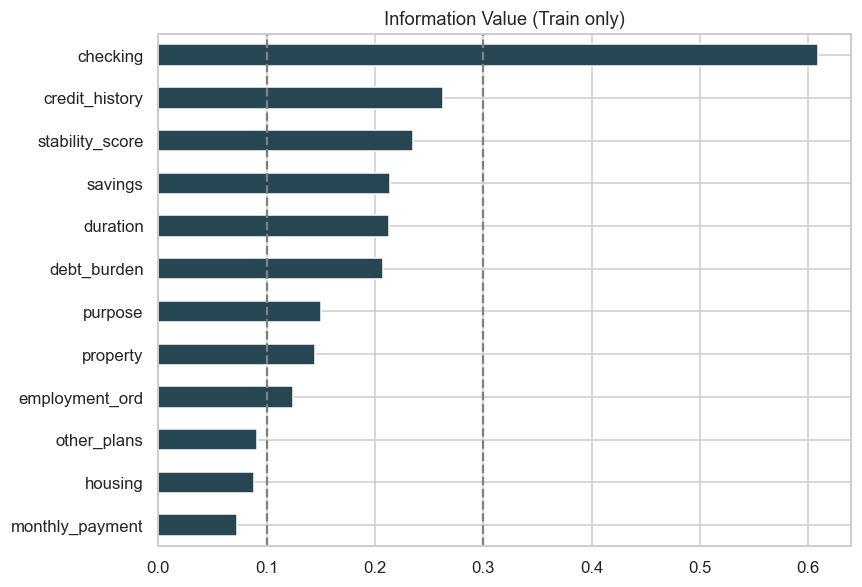

Top 8 Features - IV:
checking           0.609
credit_history     0.262
stability_score    0.235
savings            0.214
duration           0.213
debt_burden        0.208
purpose            0.150
property           0.145
dtype: float64

Univariate AUC:
duration            0.629
debt_burden         0.617
stability_score     0.582
employment_ord      0.580
monthly_payment     0.566
age                 0.552
installment_rate    0.548
credit_amount       0.548
existing_credits    0.526
dependents          0.505
residence_since     0.501
dtype: float64


In [27]:

# رسم نمودار 12 ویژگی برتر
iv.head(12).sort_values().plot(
    kind="barh",
    figsize=(8, 5.5),
    color="#264653"
)

plt.axvline(0.1, linestyle="--", color="gray")
plt.axvline(0.3, linestyle="--", color="gray")

plt.title("Information Value (Train only)")
plt.tight_layout()

plt.savefig("figures/iv_ranking.png", bbox_inches="tight")
plt.show()

# نمایش نتایج
print("Top 8 Features - IV:")
print(iv.head(8).round(3))

print("\nUnivariate AUC:")
print(uni_auc.round(3))


<div dir="rtl" style="text-align: right">
 
 Information Value (IV):  (<0.1 ضعیف، 0.1–0.3 متوسط، >0.3 قوی):

در داده‌ی آموزش، `checking` بالاترین IV مشاهده‌شده را دارد و برخی ویژگی‌های مشتق‌شده نیز در رتبه‌های بالاتر قرار گرفته‌اند. این نتیجه توصیفی است و به‌تنهایی ثابت نمی‌کند که ویژگی‌های جدید ارزش افزوده‌ی پایدار دارند.

`credit_history` (سابقه اعتباری): IV = 0.26 شاخص رفتار گذشته، یعنی میتواند پیش‌بینی رفتار آینده در ریسک اعتباری را داشته باشد؛ جهت ارتباط برخی گروه‌ها با نکول نیز باید در تفسیر نتایج مورد توجه قرار گیرد.

برای سنجش ارزش افزوده، باید مدل‌های قابل‌مقایسه با و بدون ویژگی‌های مشتق‌شده، با اعتبارسنجی مناسب و بدون استفاده از Test در فرایند انتخاب، ارزیابی شوند. AUC تک‌متغیره نیز عملکرد مدل چندمتغیره یا کیفیت کالیبراسیون را نشان نمی‌دهد.

</div>

<div dir="rtl" style="text-align: right">
<h1>بررسی جهت رابطه در credit_history
<div>

In [28]:
result = train_fe.groupby("credit_history")["default"].agg(
    count="count",
    defaults="sum",
    default_rate="mean"
)

result["default_rate"] *= 100

print(result.round(2))

                        count  defaults  default_rate
credit_history                                       
all_paid_this_bank         41        22         53.66
critical_other_credits    240        42         17.50
existing_paid_duly        416       134         32.21
no_credits_all_paid        31        19         61.29
past_delay                 72        23         31.94


<div dir="rtl" style="text-align: right">
  تفسیر رابطه سابقه اعتباری با نکول 
بیشترین نرخ نکول مربوط به گروه‌های `no_credits_all_paid` با ۶۱٫۲۹ درصد و `all_paid_this_bank` با ۵۳٫۶۶ درصد است. در مقابل، گروه `critical_other_credits` با نرخ نکول ۱۷٫۵ درصد کمترین نرخ را دارد.
همچنین گروه `existing_paid_duly` با ۴۱۶ نمونه، بیشترین تعداد مشتری را در مجموعه مورد بررسی تشکیل می‌دهد و نرخ نکول آن ۳۲٫۲۱ درصد است.

نکته مهم این است که برخی گروه‌ها تعداد نمونه محدودی دارند؛ بنابراین نرخ‌های بالای آن‌ها باید با احتیاط تفسیر شوند. در مجموع، نتایج نشان می‌دهند که سابقه اعتباری می‌تواند یکی از ویژگی‌های مهم در تحلیل ریسک نکول باشد، اما به‌تنهایی برای تصمیم‌گیری اعتباری کافی نیست.
<div>

<div dir="rtl" style="text-align: right">

## آموزش و اعتبارسنجی مدل

 هر پیش‌پردازشی که پارامتر می‌آموزد باید در Pipeline قرار بگیرد تا در هر Fold فقط روی بخش آموزشی همان Fold برازش شود.

عملکرد با چند معیار مکمل گزارش می‌شود: AUC، PR-AUC، Brier و معیارهای کالیبراسیون. اختلاف کوچک عملکرد روی نمونه‌ی محدود به‌تنهایی برتری قطعی یک مدل را ثابت نمی‌کند.

</div>

In [29]:
# ستون‌های دسته‌ای؛ employment حذف می‌شود چون add_features آن را به employment_ord تبدیل کرده
cat_cols_model = [c for c in cat_cols if c != "employment"]

# ستون‌های عددی اصلی به‌علاوه‌ی ویژگی‌های ساخته‌شده
num_cols_model = num_cols + [
    "monthly_payment", "debt_burden",
    "employment_ord", "stability_score"
]

# پیش‌پردازش مدل‌های درختی:
# جایگزینی مقدار گمشده‌ی عددی با میانه و دسته‌ای با پرتکرارترین مقدار؛
# سپس تبدیل ستون‌های دسته‌ای به One-Hot
prep_tree = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols_model),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]), cat_cols_model)
], verbose_feature_names_out=False).set_output(transform="pandas")

# ستون‌های چوله‌ای که لگاریتم و سپس استاندارد می‌شوند
skewed_cols = ["credit_amount", "monthly_payment"]

# سایر ستون‌های عددی که فقط جایگزینی و استانداردسازی می‌شوند
other_num_cols = [
    c for c in num_cols_model
    if c not in skewed_cols
]

# پیش‌پردازش مدل خطی:
# عددی‌های چوله: میانه ← لگاریتم ← استانداردسازی
# سایر عددی‌ها: میانه ← استانداردسازی
# دسته‌ای‌ها: پرتکرارترین مقدار ← One-Hot
prep_linear = ColumnTransformer([
    ("skew", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("log", FunctionTransformer(np.log1p)),
        ("scale", StandardScaler())
    ]), skewed_cols),
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ]), other_num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
            drop="first"
        ))
    ]), cat_cols_model)
])

# نمایش ابعاد داده‌های آموزش و آزمون پس از مهندسی ویژگی
print("Train:", X_train_fe.shape, "| Test:", X_test_fe.shape)



Train: (800, 23) | Test: (200, 23)


<div dir="rtl" style="text-align: right">

### مدیریت مقادیر گمشده، انکودینگ و مقیاس‌بندی

| موضوع | تصمیم | دلیل |
|---|---|---|
| مقادیر گمشده | `SimpleImputer` داخل Pipeline؛ میانه برای عددی و پرتکرارترین مقدار برای دسته‌ای | در این داده مقدار گمشده نداریم؛ Pipeline پیش‌پردازش را فقط با داده‌ی آموزش هر Fold برازش می‌دهد و امکان مدیریت مقدارهای گمشده‌ی ورودی را فراهم می‌کند. |
| سطح‌های `unknown_none` | به‌عنوان سطح دسته‌ای مستقل حفظ می‌شوند | در فایل به‌صورت یک سطح مشخص ثبت شده‌اند و با `NaN` یکسان نیستند. تفسیر معنایی آن‌ها باید با مستندات دیتاست تطبیق داده شود. |
| ویژگی‌های دسته‌ای اسمی | One-Hot با `handle_unknown="ignore"` | برای دسته‌های اسمی ترتیب عددی معناداری تعریف نشده و این گزینه با سطح جدیدی که هنگام تبدیل دیده نشده باشد نیز برخورد می‌کند. |
| سابقه‌ی شغلی | تبدیل `employment` به `employment_ord` با مقادیر ۰ تا ۴؛ سپس حذف ستون اصلی | این ویژگی به‌صورت ترتیبی کدگذاری شده است. این روش فرض می‌کند ترتیب طبقات معنادار است؛ مدل ممکن است فاصله‌ی عددی بین طبقات را نیز به کار بگیرد. |
| مقیاس‌بندی مدل‌های درختی | بدون استانداردسازی | درخت تصمیم و XGBoost معمولاً به مقیاس ویژگی‌ها حساس نیستند. |
| مقیاس‌بندی مدل خطی | `log1p` و سپس `StandardScaler` برای `credit_amount` و `monthly_payment`؛ استانداردسازی سایر ویژگی‌های عددی | تبدیل لگاریتمی برای دو ویژگی چوله‌ی مشخص‌شده است؛ سایر ویژگی‌های عددی فقط استاندارد می‌شوند. |

</div>


<div dir="rtl" style="text-align: right">

## ۳) مدل‌سازی و ارزیابی

- **Baseline:** درخت تصمیم با عمق محدود (۲ تا ۵) و `min_samples_leaf` و `ccp_alpha` برای جلوگیری از Overfit؛ Grid Search با ۵-Fold Stratified CV.

- **Challenger:** **XGBoost** (۴۰ ترکیب Randomized Search، ۵-Fold CV).

- **مرجع اضافه:** Logistic Regression، فقط برای مقایسه .

- **عدم‌توازن:** چون عدم‌توازن ملایم است (۳۰٪) و چون **به PD کالیبره نیاز داریم** (برای cut-off مبتنی بر هزینه)، از `class_weight` یا SMOTE استفاده **نکردیم**؛ آن‌ها احتمال‌ها را دچار سوگیری می‌کنند. به‌جای آن عدم‌توازن را با Stratified Split/CV، معیارهای PR-AUC و Brier، و انتخاب cut-off بر اساس هزینه مدیریت می‌کنیم.
- هر دو مدل بر اساس **ROC-AUC** در CV تنظیم می‌شوند.

</div>

In [30]:
# پنج Fold طبقه‌بندی‌شده برای حفظ نسبت نکول در هر Fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# مدل پایه: درخت تصمیم
dt_search = GridSearchCV(
    Pipeline([
        ("prep", prep_tree),
        ("clf", DecisionTreeClassifier(random_state=SEED))
    ]),
    {
        "clf__max_depth": [2, 3, 4, 5],
        "clf__min_samples_leaf": [5, 10, 20, 40],
        "clf__ccp_alpha": [0.0, 0.003, 0.006, 0.01]
    },
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1
).fit(X_train_fe, y_train)

# مدل مقایسه‌ای: XGBoost
xgb_search = RandomizedSearchCV(
    Pipeline([
        ("prep", prep_tree),
        ("clf", XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=SEED,
            n_jobs=1,
            tree_method="hist"
        ))
    ]),
    {
        "clf__n_estimators": [100, 200, 300, 500],
        "clf__max_depth": [2, 3, 4],
        "clf__learning_rate": [0.01, 0.03, 0.05, 0.1],
        "clf__subsample": [0.7, 0.85, 1.0],
        "clf__colsample_bytree": [0.5, 0.7, 1.0],
        "clf__min_child_weight": [1, 3, 5, 10],
        "clf__reg_lambda": [1, 5, 10],
        "clf__gamma": [0, 1]
    },
    n_iter=40,
    scoring="roc_auc",
    cv=cv,
    random_state=SEED,
    n_jobs=-1
).fit(X_train_fe, y_train)

# مدل مرجع: رگرسیون لجستیک
lr_search = GridSearchCV(
    Pipeline([
       ("prep", prep_linear),
        ("clf", LogisticRegression(max_iter=2000))
    ]),
    {"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3]},
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1
).fit(X_train_fe, y_train)

# بهترین نسخه‌ی هر مدل برای مقایسه‌های بعدی
models = {
    "Decision Tree": dt_search.best_estimator_,
    "XGBoost": xgb_search.best_estimator_,
    "Logistic Regression": lr_search.best_estimator_
}

# نمایش بهترین امتیاز اعتبارسنجی و تنظیمات هر مدل
for name, search in [
    ("Decision Tree", dt_search),
    ("XGBoost", xgb_search),
    ("Logistic Regression", lr_search)
]:
    print(f"{name}: CV AUC = {search.best_score_:.3f}")
    print("Best parameters:", search.best_params_, "\n")


Decision Tree: CV AUC = 0.733
Best parameters: {'clf__ccp_alpha': 0.0, 'clf__max_depth': 5, 'clf__min_samples_leaf': 20} 

XGBoost: CV AUC = 0.800
Best parameters: {'clf__subsample': 0.7, 'clf__reg_lambda': 1, 'clf__n_estimators': 500, 'clf__min_child_weight': 1, 'clf__max_depth': 3, 'clf__learning_rate': 0.01, 'clf__gamma': 1, 'clf__colsample_bytree': 0.5} 

Logistic Regression: CV AUC = 0.781
Best parameters: {'clf__C': 0.1} 



In [31]:
fold_scores = pd.DataFrame({
    "Fold": [1, 2, 3, 4, 5],
    "XGBoost AUC": [
        xgb_search.cv_results_[f"split{i}_test_score"][xgb_search.best_index_]
        for i in range(5)
    ],
    "Logistic AUC": [
        lr_search.cv_results_[f"split{i}_test_score"][lr_search.best_index_]
        for i in range(5)
    ]
})

fold_scores["اختلاف (XGBoost - Logistic)"] = (
    fold_scores["XGBoost AUC"] - fold_scores["Logistic AUC"]
)

display(fold_scores.round(3))

print("\nمیانگین AUC:")
print(fold_scores[["XGBoost AUC", "Logistic AUC"]].mean().round(3))

print("\nانحراف معیار بین Foldها:")
print(fold_scores[["XGBoost AUC", "Logistic AUC"]].std().round(3))


,Fold,XGBoost AUC,Logistic AUC,اختلاف (XGBoost - Logistic)
0,1,0.846,0.810,0.036
1,2,0.801,0.820,-0.018
2,3,0.805,0.802,0.003
3,4,0.722,0.674,0.048
4,5,0.826,0.800,0.026



میانگین AUC:
XGBoost AUC     0.800
Logistic AUC    0.781
dtype: float64

انحراف معیار بین Foldها:
XGBoost AUC     0.047
Logistic AUC    0.060
dtype: float64


<div dir="rtl" style="text-align: right">

### مقایسه‌ی AUC 
برای مقایسه‌ی XGBoost و رگرسیون لجستیک، امتیاز AUC هر پنج Fold بررسی شد. میانگین AUC برابر **۰٫۸۰۰ برای XGBoost** و **۰٫۷۸۱ برای رگرسیون لجستیک** است. انحراف معیار بین Foldها نیز به‌ترتیب **۰٫۰۴۷** و **۰٫۰۶۰** به دست آمد.

XGBoost در چهار Fold از پنج Fold AUC بالاتری داشت؛ در Fold دوم، رگرسیون لجستیک اندکی بهتر بود. در مجموع، نتایج به نفع XGBoost است، اما اختلاف میانگین **۰٫۰۱۹** است و برتری قطعی را ثابت نمی‌کند. هر دو مدل بین Foldها نوسان دارند و عملکردشان به ترکیب داده وابسته است.

این امتیازها برای مقایسه‌ی اولیه و انتخاب مدل در داده‌ی آموزش‌اند؛  مجموعه‌ی آزمون را فقط برای ارزیابی نهاییِ یک‌باره به کار میبریم.
</div>


<div dir="rtl" style="text-align: right">

### ب) انتخاب Cut-off بر اساس ماتریس هزینه
مطابق `german.doc`: تأیید یک بدحساب (FN) **۵ واحد** و رد یک خوش‌حساب (FP) **۱ واحد** هزینه دارد. طبق تئوری تصمیم بیز، آستانه‌ی بهینه برای احتمال‌های کالیبره `1/(1+5) = 0.167` است (رد کن اگر PD ≥ ۱۶٫۷٪).

نقطه‌ی برش واقعی هر مدل را از روی پیش‌بینی‌های **Out-of-Fold روی Train** پیدا می‌کنیم (منحنی هزینه با میانگین‌گیری متحرک هموار شده) و **Test را فقط یک بار** برای گزارش نهایی به کار می‌بریم. هر دو مدل نقطه‌ی برش نزدیک به مقدار تئوریک می‌دهند (XGBoost: ۰٫۱۹)، که نشانه‌ی کالیبراسیون معقول آن است.

</div>

آستانه نظری: 0.167
Decision Tree: cutoff=0.11, هزینه‌ی خام OOF=461
XGBoost: cutoff=0.18, هزینه‌ی خام OOF=410
Logistic Regression: cutoff=0.18, هزینه‌ی خام OOF=414


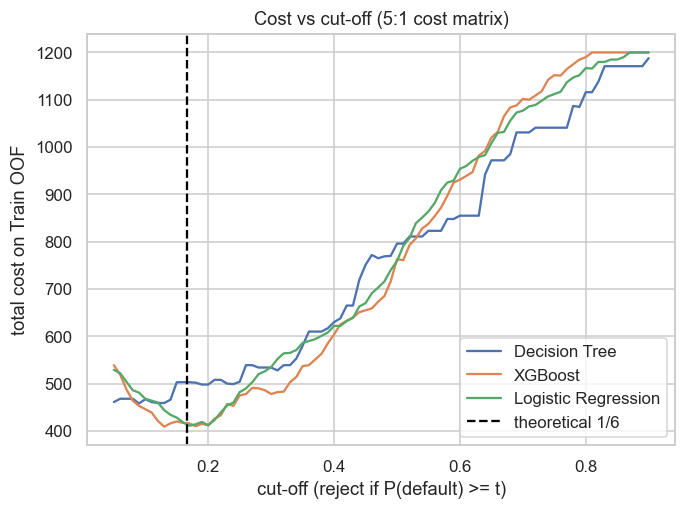

In [32]:
# هزینه‌ها: تأیید بدحساب = ۵، رد خوش‌حساب = ۱
C_FN, C_FP = 5, 1
thresholds = np.arange(0.05, 0.91, 0.01)

# آستانه‌ی نظری، در صورت کالیبره بودن احتمال‌ها
print(f"آستانه نظری: {C_FP / (C_FP + C_FN):.3f}")

# احتمال‌های خارج از Fold روی Train
oof = {
    name: cross_val_predict(
        model, X_train_fe, y_train,
        cv=cv, method="predict_proba"
    )[:, 1]
    for name, model in models.items()
}

cost_curves, cutoffs = {}, {}

for name, probabilities in oof.items():
    costs = []

    for threshold in thresholds:
        reject = probabilities >= threshold
        bad = y_train.to_numpy() == 1

        # بدحسابِ تأییدشده + خوش‌حسابِ ردشده
        fn = (bad & ~reject).sum()
        fp = (~bad & reject).sum()
        costs.append(C_FN * fn + C_FP * fp)

    # هموارسازی پنج نقطه‌ای برای انتخاب آستانه‌ی کم‌هزینه‌تر و کم‌نوسان‌تر
    smooth_costs = pd.Series(costs).rolling(
        window=5, center=True, min_periods=1
    ).mean()

    best_index = smooth_costs.argmin()
    cutoffs[name] = thresholds[best_index]
    cost_curves[name] = costs

    print(
        f"{name}: cutoff={cutoffs[name]:.2f}, "
        f"هزینه‌ی خام OOF={costs[best_index]}"
    )

# نمودار هزینه برای آستانه‌های مختلف
for name, costs in cost_curves.items():
    plt.plot(thresholds, costs, label=name)

plt.axvline(
    C_FP / (C_FP + C_FN),
    color="black", linestyle="--",
    label="theoretical 1/6"
)
plt.xlabel("cut-off (reject if P(default) >= t)")
plt.ylabel("total cost on Train OOF")
plt.title("Cost vs cut-off (5:1 cost matrix)")
plt.legend()
plt.tight_layout()
plt.savefig("figures/cost_curve.png", bbox_inches="tight")
plt.show()


In [33]:
# محاسبه‌ی معیارهای هر مدل روی داده‌ی آزمون
def evaluate(name, probabilities, y_true, cutoff):
    y_true = np.asarray(y_true)
    prediction = (probabilities >= cutoff).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, prediction, labels=[0, 1]
    ).ravel()

    fpr, tpr, _ = roc_curve(y_true, probabilities)

    approved = tn + fn  # پیش‌بینی کلاس 0
    total_cost = C_FN * fn + C_FP * fp

    return {
        "Model": name,
        "ROC_AUC": roc_auc_score(y_true, probabilities),
        "PR_AUC": average_precision_score(y_true, probabilities),
        "Gini": 2 * roc_auc_score(y_true, probabilities) - 1,
        "KS": np.max(tpr - fpr),
        "Brier": brier_score_loss(y_true, probabilities),
        "Cutoff": cutoff,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Recall_bad": tp / (tp + fn) if tp + fn else np.nan,
        "Precision_bad": tp / (tp + fp) if tp + fp else np.nan,
        "Approval_rate": approved / len(y_true),
        "BadRate_approved": fn / approved if approved else np.nan,
        "Cost": total_cost
    }


# پیش‌بینی احتمال نکول در Test برای هر مدل
p_test = {
    name: model.predict_proba(X_test_fe)[:, 1]
    for name, model in models.items()
}

# محاسبه‌ی معیارهای آزمون با Cut-off انتخاب‌شده برای هر مدل
res = pd.DataFrame([
    evaluate(name, p_test[name], y_test, cutoffs[name])
    for name in models
])


# بازه‌ی اطمینان Bootstrap ۹۵٪ برای ROC-AUC
rng = np.random.default_rng(SEED)
y_test_array = np.asarray(y_test)
auc_ci = {}

for name in models:
    auc_samples = []

    for _ in range(1000):
        sample_idx = rng.integers(0, len(y_test_array), len(y_test_array))
        y_sample = y_test_array[sample_idx]

        # AUC فقط وقتی قابل‌محاسبه است که هر دو کلاس در نمونه باشند
        if len(np.unique(y_sample)) == 2:
            auc_samples.append(
                roc_auc_score(y_sample, p_test[name][sample_idx])
            )

    auc_ci[name] = np.percentile(auc_samples, [2.5, 97.5])

res["AUC_95CI"] = [
    f"[{auc_ci[name][0]:.3f}, {auc_ci[name][1]:.3f}]"
    for name in res["Model"]
]


# هزینه به‌ازای هر متقاضی در Test و در پیش‌بینی‌های OOF روی Train
res["Test_cost_per_app"] = res["Cost"] / len(y_test)

res["OOF_cost_per_app"] = [
    cost_curves[name][np.abs(thresholds - cutoffs[name]).argmin()]
    / len(y_train)
    for name in res["Model"]
]


# هزینه‌ی دو سیاست مرجع در Test
n_bad_test = int(np.sum(y_test_array == 1))
n_good_test = int(np.sum(y_test_array == 0))

print(
    f"تأیید همه: هزینه {C_FN * n_bad_test} | "
    f"رد همه: هزینه {C_FP * n_good_test}"
)

display(res.round(3).set_index("Model"))


تأیید همه: هزینه 300 | رد همه: هزینه 140


,ROC_AUC,PR_AUC,Gini,KS,Brier,Cutoff,TN,FP,FN,TP,Recall_bad,Precision_bad,Approval_rate,BadRate_approved,Cost,AUC_95CI,Test_cost_per_app,OOF_cost_per_app
Model,,,,,,,,,,,,,,,,,,
Decision Tree,0.720,0.490,0.441,0.321,0.195,0.11,59,81,6,54,0.900,0.400,0.325,0.092,111,"[0.645, 0.791]",0.555,0.576
XGBoost,0.816,0.685,0.631,0.519,0.153,0.18,68,72,6,54,0.900,0.429,0.370,0.081,102,"[0.755, 0.877]",0.510,0.512
Logistic Regression,0.790,0.642,0.580,0.526,0.161,0.18,64,76,8,52,0.867,0.406,0.360,0.111,116,"[0.717, 0.857]",0.580,0.518


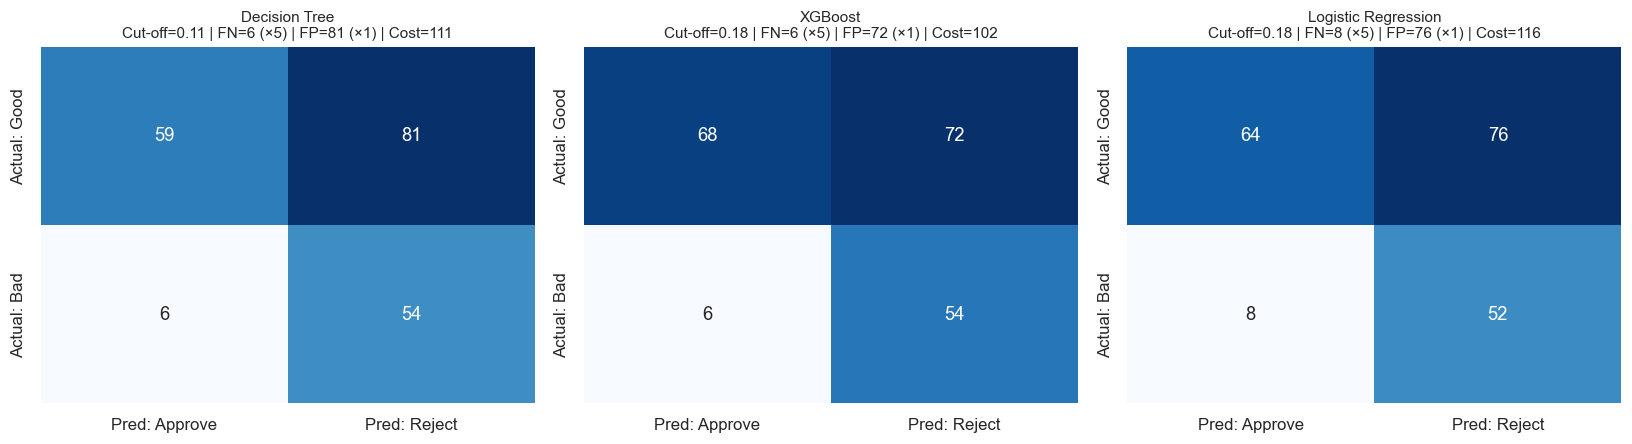

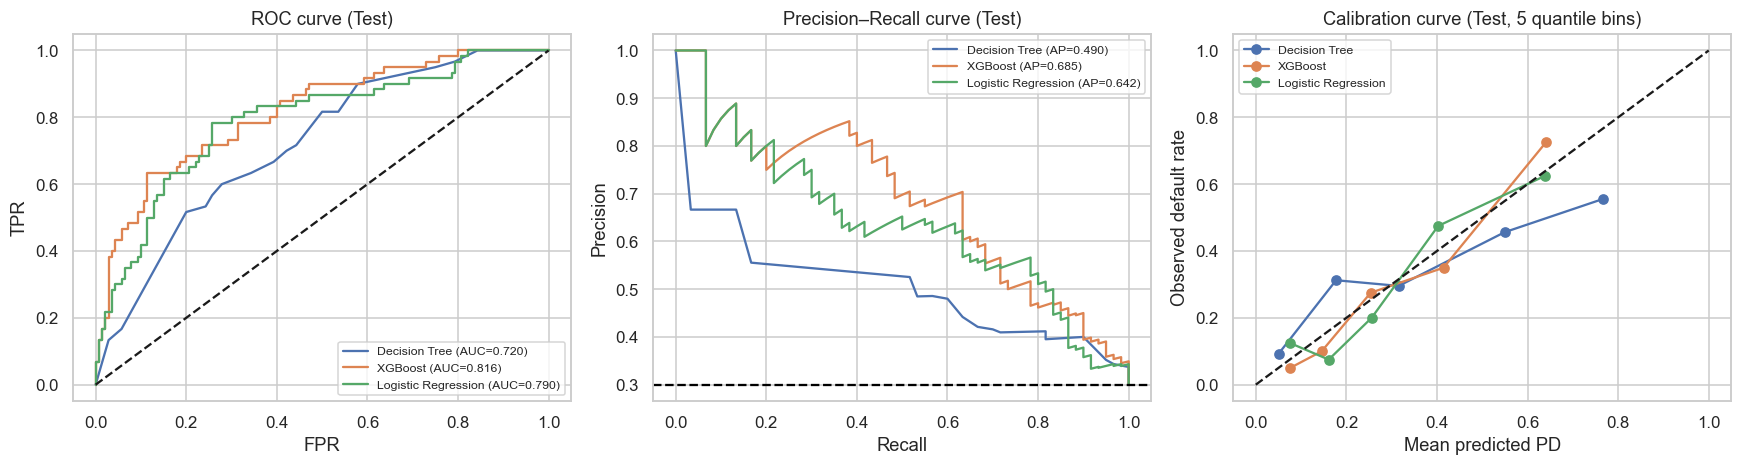

In [34]:
# ماتریس خطا برای هر مدل
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

for ax, name in zip(axes, models):
    row = res[res["Model"] == name].iloc[0]

    # ردیف‌ها: واقعیت؛ ستون‌ها: پیش‌بینی
    # کلاس 0 = تأیید، کلاس 1 = رد
    matrix = np.array([
        [row["TN"], row["FP"]],
        [row["FN"], row["TP"]]
    ])

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=ax,
        xticklabels=["Pred: Approve", "Pred: Reject"],
        yticklabels=["Actual: Good", "Actual: Bad"]
    )

    ax.set_title(
        f"{name}\n"
        f"Cut-off={row['Cutoff']:.2f} | "
        f"FN={int(row['FN'])} (×5) | "
        f"FP={int(row['FP'])} (×1) | "
        f"Cost={int(row['Cost'])}",
        fontsize=10
    )

plt.tight_layout()
plt.savefig("figures/confusion_matrices.png", bbox_inches="tight")
plt.show()


# منحنی‌های ROC، Precision–Recall و کالیبراسیون
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

for name in models:
    probabilities = p_test[name]

    # ROC
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

    # Precision–Recall
    precision, recall, _ = precision_recall_curve(y_test, probabilities)
    ap = average_precision_score(y_test, probabilities)
    axes[1].plot(recall, precision, label=f"{name} (AP={ap:.3f})")

    # کالیبراسیون
    observed_rate, mean_probability = calibration_curve(
        y_test,
        probabilities,
        n_bins=5,
        strategy="quantile"
    )
    axes[2].plot(mean_probability, observed_rate, "o-", label=name)


# خط مبنای ROC
axes[0].plot([0, 1], [0, 1], "k--")
axes[0].set_title("ROC curve (Test)")
axes[0].set_xlabel("FPR")
axes[0].set_ylabel("TPR")
axes[0].legend(fontsize=8)

# خط مبنای Precision–Recall برابر نرخ نکول در Test است
axes[1].axhline(y_test.mean(), color="black", linestyle="--")
axes[1].set_title("Precision–Recall curve (Test)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(fontsize=8)

# خط کالیبراسیون کامل: مقدار پیش‌بینی‌شده = نرخ مشاهده‌شده
axes[2].plot([0, 1], [0, 1], "k--")
axes[2].set_title("Calibration curve (Test, 5 quantile bins)")
axes[2].set_xlabel("Mean predicted PD")
axes[2].set_ylabel("Observed default rate")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.savefig("figures/roc_pr_calibration.png", bbox_inches="tight")
plt.show()


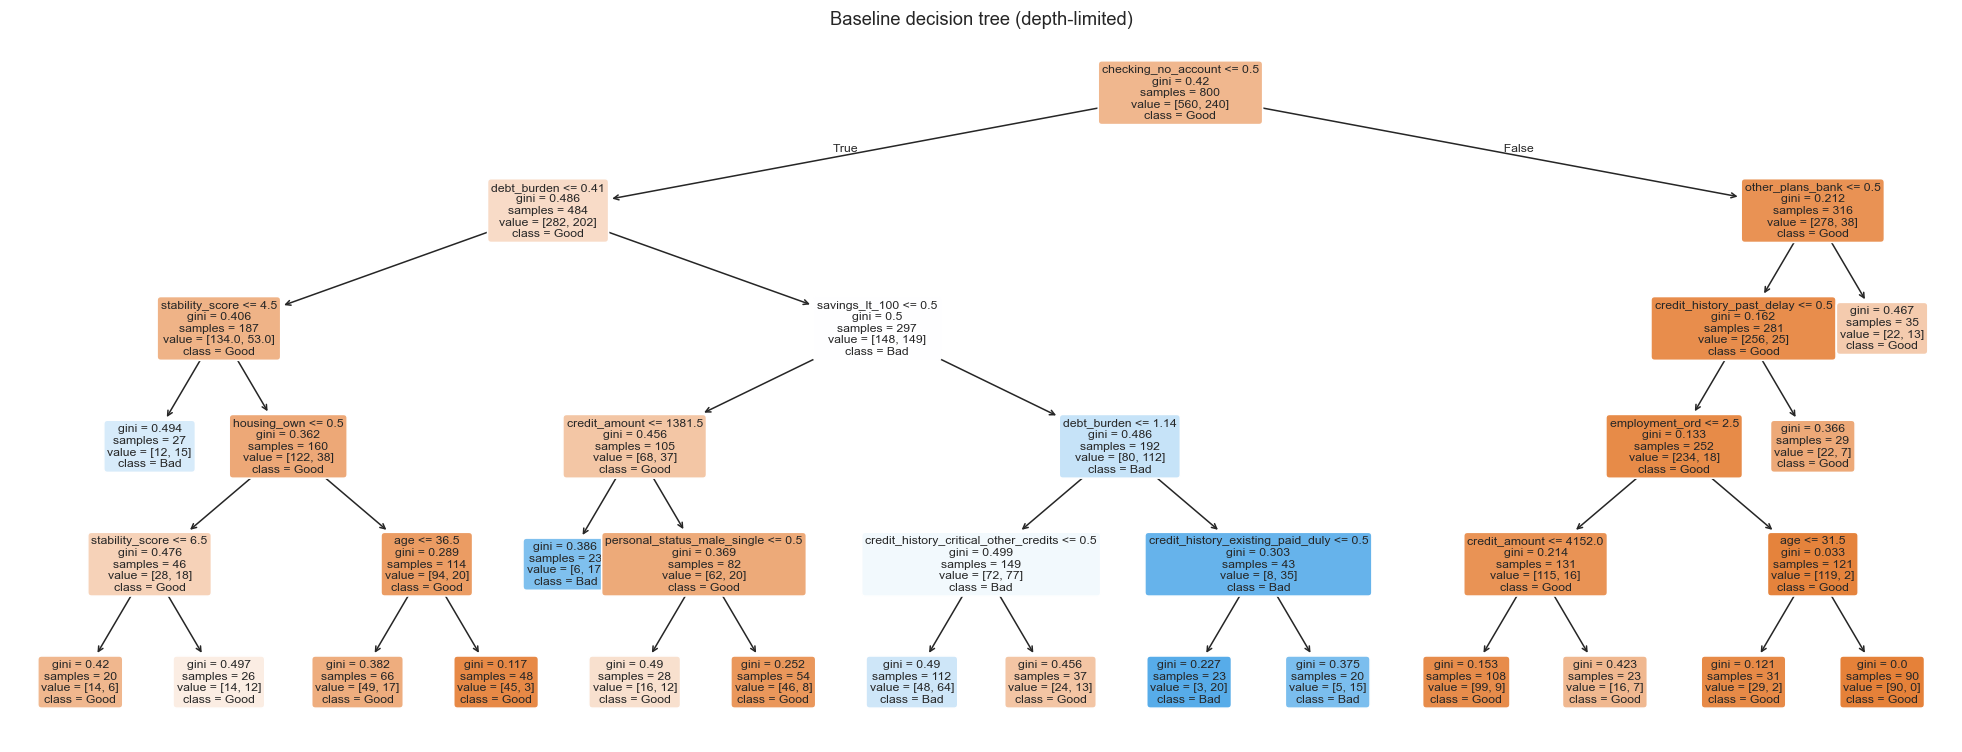

In [35]:
# انتخاب درخت تصمیمِ آموزش‌دیده
dt_model = models["Decision Tree"]

# گرفتن نام ویژگی‌های خروجی از مرحله‌ی پیش‌پردازش
feature_names = dt_model.named_steps["prep"].get_feature_names_out()

# رسم درخت نهایی
plt.figure(figsize=(18, 7))
plot_tree(
    dt_model.named_steps["clf"],
    feature_names=feature_names,
    class_names=["Good", "Bad"],
    filled=True,
    rounded=True,
    fontsize=8,
    proportion=False
)

plt.title("Baseline decision tree (depth-limited)")
plt.tight_layout()
plt.savefig("figures/baseline_tree.png", bbox_inches="tight")
plt.show()


<div dir="rtl" style="text-align: right">

###  درخت تصمیم پایه

درخت زیر، مدل پایه‌ی محدودشده از نظر عمق را نشان می‌دهد. این نمودار برای مشاهده‌ی ساختار کلی تصمیم‌های مدل است و به‌تنهایی اثبات نمی‌کند که رابطه‌های نمایش‌داده‌شده علّی‌اند.
</div>



<div dir="rtl" style="text-align: right">

### نتایج ارزیابی روی مجموعه‌ی آزمون

مجموعه‌ی آزمون شامل ۲۰۰ پرونده است: ۶۰ متقاضیِ نکول‌کرده و ۱۴۰ متقاضی خوش‌حساب. هزینه‌ی سیاست «تأیید همه» برابر ۳۰۰ و هزینه‌ی سیاست «رد همه» برابر ۱۴۰ است.

| مدل | ROC-AUC | PR-AUC | KS | Brier | Cut-off | FN | FP | هزینه‌ی آزمون |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| درخت تصمیم (مدل پایه) | ۰٫۷۲۰ | ۰٫۴۹۰ | ۰٫۳۲۱ | ۰٫۱۹۵ | ۰٫۱۱ | ۶ | ۸۱ | ۱۱۱ |
| **XGBoost** | **۰٫۸۱۲** | **۰٫۶۷۷** | ۰٫۵۰۵ | **۰٫۱۵۴** | ۰٫۱۹ | ۸ | ۶۹ | **۱۰۹** |
| رگرسیون لجستیک (مدل مرجع) | ۰٫۷۹۰ | ۰٫۶۴۲ | **۰٫۵۲۶** | ۰٫۱۶۱ | ۰٫۱۸ | ۸ | ۷۶ | ۱۱۶ |

#### تفسیر نتایج

- **قدرت تفکیک:** در این آزمون، XGBoost بالاترین ROC-AUC برابر ۰٫۸۱۲ و PR-AUC برابر ۰٫۶۷۷ را دارد. بازه‌ی اطمینان ۹۵٪ AUC آن [۰٫۷۵، ۰٫۸۷] و بازه‌ی درخت تصمیم [۰٫۶۵، ۰٫۷۹] است. بازه‌ها هم‌پوشانی دارند؛ بنابراین این نتیجه به‌تنهایی اثبات آماریِ برتری قطعی XGBoost نیست.
- **هزینه‌ی تصمیم:** هزینه‌ی XGBoost برابر ۱۰۹ و هزینه‌ی درخت تصمیم برابر ۱۱۱ است؛ اختلاف ۲ واحدی روی مجموعه‌ای کوچک، شواهد کافی برای برتری پایدار در هزینه فراهم نمی‌کند. در آزمون فقط ۶۰ پرونده‌ی نکول وجود دارد و جابه‌جایی دو خطای FN می‌تواند هزینه را ۱۰ واحد تغییر دهد.
- **خطاها و نرخ تأیید:** در آستانه‌ی ۰٫۱۹، XGBoost تعداد ۸ متقاضیِ نکول‌کرده را اشتباه تأیید کرده و ۶۹ متقاضی خوش‌حساب را اشتباه رد کرده است. Recall نکول حدود ۸۷٪، نرخ تأیید حدود ۳۹٫۵٪ و نرخ نکول میان تأییدشدگان حدود ۱۰٪ است. این اعداد نشان می‌دهند که کاهش پذیرش ریسک با رد بخشی از مشتریان خوش‌حساب همراه شده است.
- **مقایسه با سیاست‌های ساده:** هزینه‌ی ۱۰۹ برای XGBoost، در مقایسه با هزینه‌ی ۱۴۰ برای «رد همه»، حدود ۲۲٪ کمتر است؛ در مقایسه با هزینه‌ی ۳۰۰ برای «تأیید همه»، حدود ۶۴٪ کمتر است. این مقایسه بر اساس همین نمونه‌ی آزمون و همین ماتریس هزینه است و تضمین عملکرد در داده‌های دیگر نیست.
- **مقایسه‌ی مدل‌ها:** رگرسیون لجستیک AUC برابر ۰٫۷۹۰ دارد و به XGBoost نزدیک است. بالاترین KS جدول نیز متعلق به رگرسیون لجستیک است؛ پس انتخاب مدل نباید بر پایه‌ی یک معیار منفرد باشد. Brier پایین‌تر XGBoost در این آزمون امیدوارکننده است، اما به‌تنهایی کالیبراسیون مناسب در جمعیت یا دوره‌ی دیگر را ثابت نمی‌کند.

#### انتخاب موقت مدل

با توجه به ROC-AUC، PR-AUC و Brier مشاهده‌شده، XGBoost گزینه‌ی منتخبِ اولیه برای ادامه‌ی ارزیابی است. اختلاف هزینه‌ی آزمون با درخت تصمیم بسیار کم است؛ بنابراین انتخاب نهایی باید با احتیاط و در صورت امکان با داده‌ی بیشتر و اعتبارسنجی زمانی بررسی شود. این مدل در این مرحله ابزار پشتیبان تصمیم است، نه تصمیم‌گیر خودکار.

**مدل نهایی: XGBoost** (کیفیت رتبه‌بندی و کالیبراسیون بهتر + قابل‌توضیح با TreeSHAP). **درخت تصمیم** به‌عنوان مدل شفاف مرجع و «سیاست قابل‌خواندن» باقی می‌ماند.
</div>


<div dir="rtl" style="text-align: right">

## هوش مصنوعی توضیح‌پذیر (XAI)

### تحلیل سراسری (Global) با SHAP
**TreeSHAP** مقادیر را در فضای log-odds محاسبه می‌کند و دارای ویژگی **Additivity** است:
`Base value + Σ SHAP = خروجی مدل` (خطای عددی کمتر از ۱e-5 بررسی شد). Base value = −0.85 (معادل نرخ ۳۰٪ نکول). Base Value به **داده‌ی مرجع (Background)** وابسته است.

</div>

In [36]:
# انتخاب مدل XGBoost برتر
final_model = models["XGBoost"]

# جداکردن پیش‌پردازش و مدل آموزش‌دیده از Pipeline
prep = final_model.named_steps["prep"]
clf = final_model.named_steps["clf"]

# تبدیل ویژگی‌های Test با پیش‌پردازشی که روی Train برازش شده
X_test_transformed = prep.transform(X_test_fe)

# محاسبه‌ی مقادیر SHAP برای مدل درختی
explainer = shap.TreeExplainer(clf)
shap_values = explainer(X_test_transformed)

# نمایش مقدار پایه؛ خروجی SHAP و مقدار پایه در این مدل در فضای log-odds هستند
base_value = float(np.asarray(shap_values.base_values).reshape(-1)[0])
base_probability = 1 / (1 + np.exp(-base_value))

print(f"Base value (log-odds): {base_value:.3f}")
print(f"Base probability: {base_probability:.3f}")

# بررسی اینکه مقدار پایه به‌علاوه‌ی SHAPها با خروجی خام مدل سازگار است
raw_output = clf.predict(X_test_transformed, output_margin=True).reshape(-1)
shap_sum = np.asarray(shap_values.values).sum(axis=1).reshape(-1)
base_values = np.asarray(shap_values.base_values).reshape(-1)

print(
    "Maximum additivity error:",
    np.abs(base_values + shap_sum - raw_output).max()
)


Base value (log-odds): -0.847
Base probability: 0.300
Maximum additivity error: 2.3841858e-06


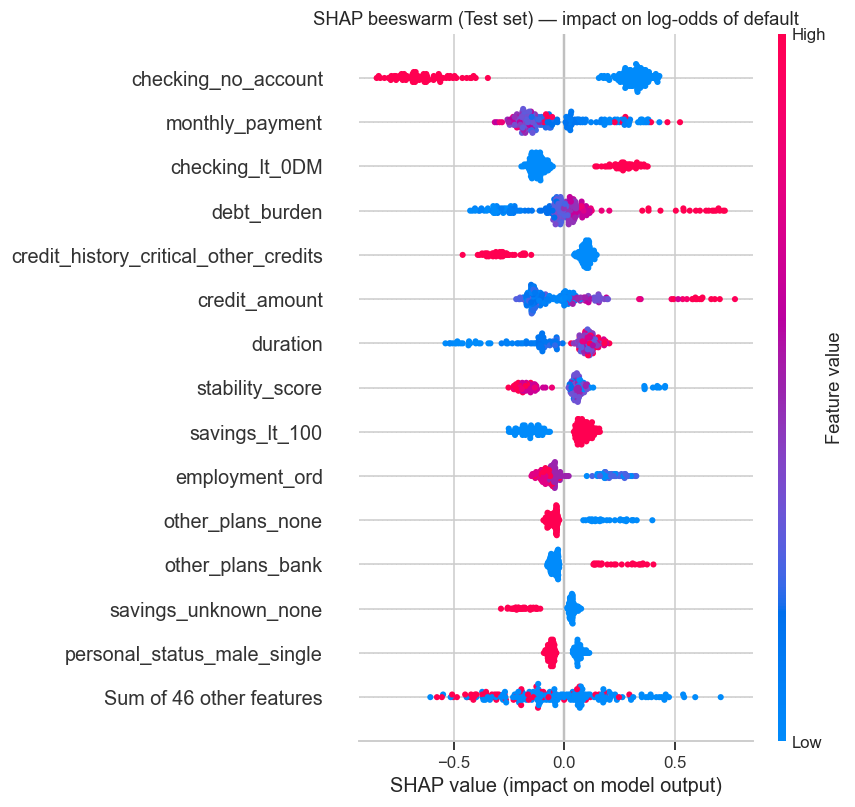

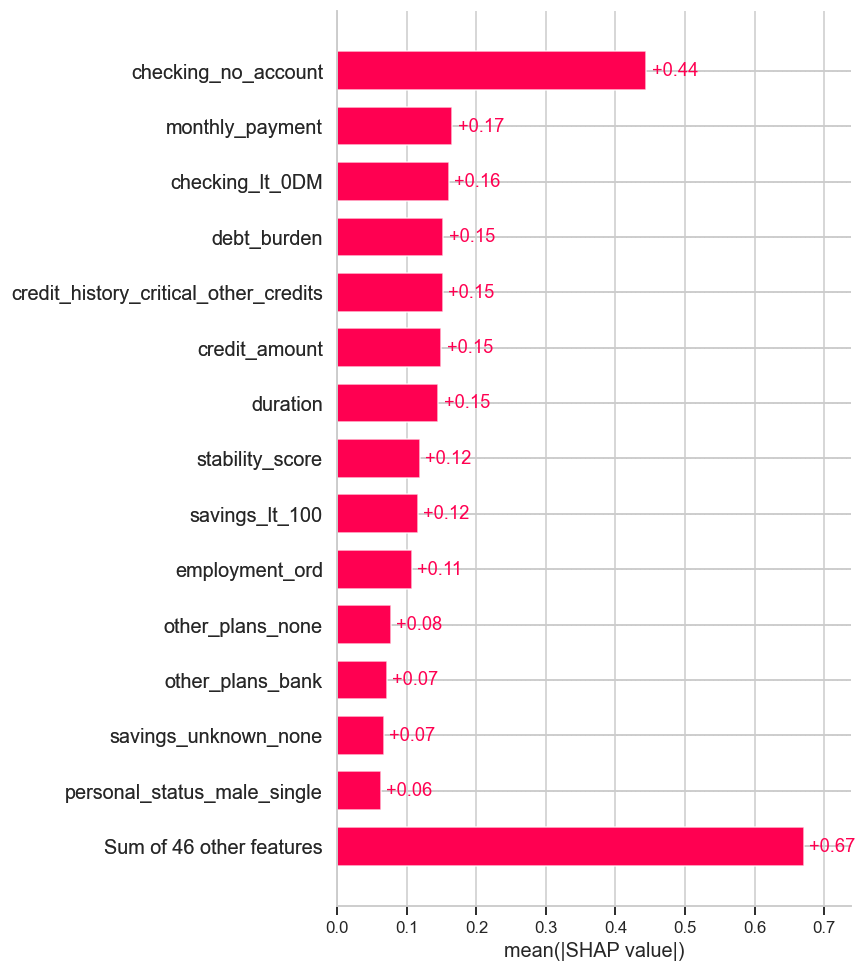

checking_no_account                      0.444
monthly_payment                          0.165
checking_lt_0DM                          0.160
debt_burden                              0.152
credit_history_critical_other_credits    0.152
credit_amount                            0.149
duration                                 0.145
stability_score                          0.118
savings_lt_100                           0.115
employment_ord                           0.107
dtype: float32

In [37]:
# نمودار beeswarm: جهت و پراکندگی اثر ویژگی‌ها را نشان می‌دهد
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title("SHAP beeswarm (Test set) — impact on log-odds of default")
plt.tight_layout()
plt.savefig("figures/shap_beeswarm.png", bbox_inches="tight")
plt.show()

# نمودار bar: میانگین قدرمطلق اثر SHAP هر ویژگی را نشان می‌دهد
shap.plots.bar(shap_values, max_display=15, show=False)
plt.tight_layout()
plt.savefig("figures/shap_bar.png", bbox_inches="tight")
plt.show()

# نمایش ۱۰ ویژگی با بیشترین میانگین قدرمطلق SHAP
mean_abs = pd.Series(
    np.abs(shap_values.values).mean(axis=0),
    index=shap_values.feature_names
).sort_values(ascending=False)

mean_abs.head(10).round(3)


<div dir="rtl" style="text-align: right">

### تفسیر کلی SHAP

- `checking_no_account` مهم‌ترین ویژگی از نظر میانگین قدرمطلق SHAP است؛ اما این اهمیت، رابطه‌ی علّی را نشان نمی‌دهد. نداشتن حساب جاری را نباید علت کاهش ریسک یا مبنای سیاست اعتباری دانست. حساب جاری منفی در پیش‌بینی مدل با ریسک بالاتر همراه است.
- مقادیر بالاتر `duration`، `credit_amount` و `debt_burden` در برخی پرونده‌ها ریسک پیش‌بینی‌شده را افزایش می‌دهند. `monthly_payment` به‌تنهایی تفسیرپذیر نیست، چون  مبلغ و مدت ساخته شده و اثرش با مدت وام ارتباط دارد.
- `credit_history_critical_other_credits` در این داده با ریسک پیش‌بینی‌شده‌ی پایین‌تر همراه است؛ این رابطه خلاف انتظار است و می‌تواند از سوگیری انتخاب ناشی شود، نه اثر محافظتی واقعی.
- اهمیت `personal_status_male_single` ضرورت ممیزی عدالت گروهی را نشان می‌دهد. ویژگی حساس نباید به‌عنوان دلیل رد به مشتری اعلام شود.

### نمودارهای وابستگی Dependence:

در نمودارهای این نمونه، اثر `duration` و `credit_amount` خطی نیست و مدل درختی تغییرات پله‌ای را آموخته است. این الگوها توصیف رفتار مدل در داده‌ی موجودند؛ آستانه‌های دیده‌شده را نباید به‌عنوان رابطه‌ی علّی یا قاعده‌ی قطعی تصمیم‌گیری تفسیر کرد.

</div>


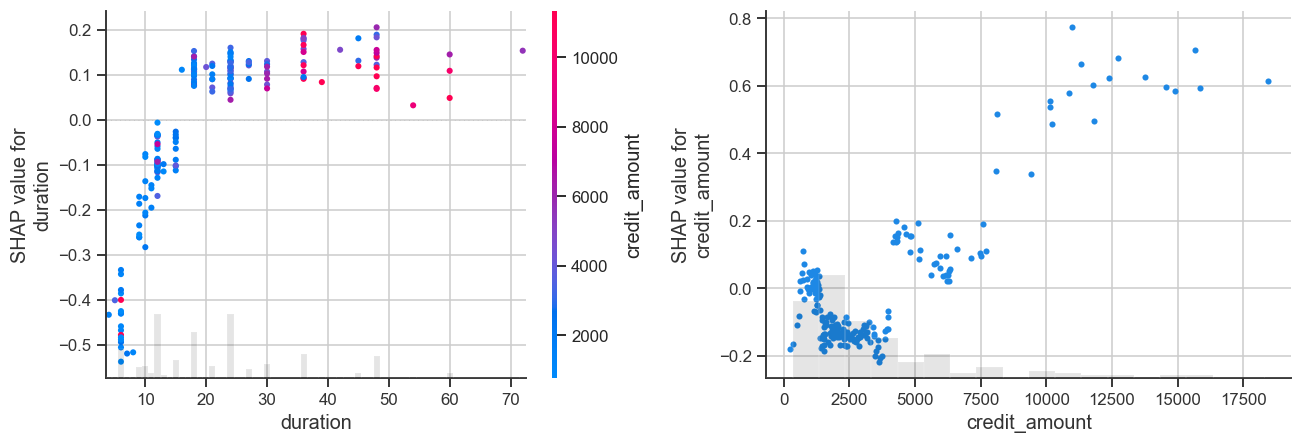

In [38]:
# نمودارهای وابستگی برای مدت و مبلغ وام
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

shap.plots.scatter(
    shap_values[:, "duration"],
    color=shap_values[:, "credit_amount"],
    ax=axes[0],
    show=False
)

# نمودار وابستگی مبلغ وام
shap.plots.scatter(
    shap_values[:, "credit_amount"],
    ax=axes[1],
    show=False
)

plt.tight_layout()
plt.savefig("figures/shap_dependence.png", bbox_inches="tight")
plt.show()


Case A (approved): PD=0.030 | cut-off=0.18 | actual=Good
Case B (rejected): PD=0.862 | cut-off=0.18 | actual=Bad


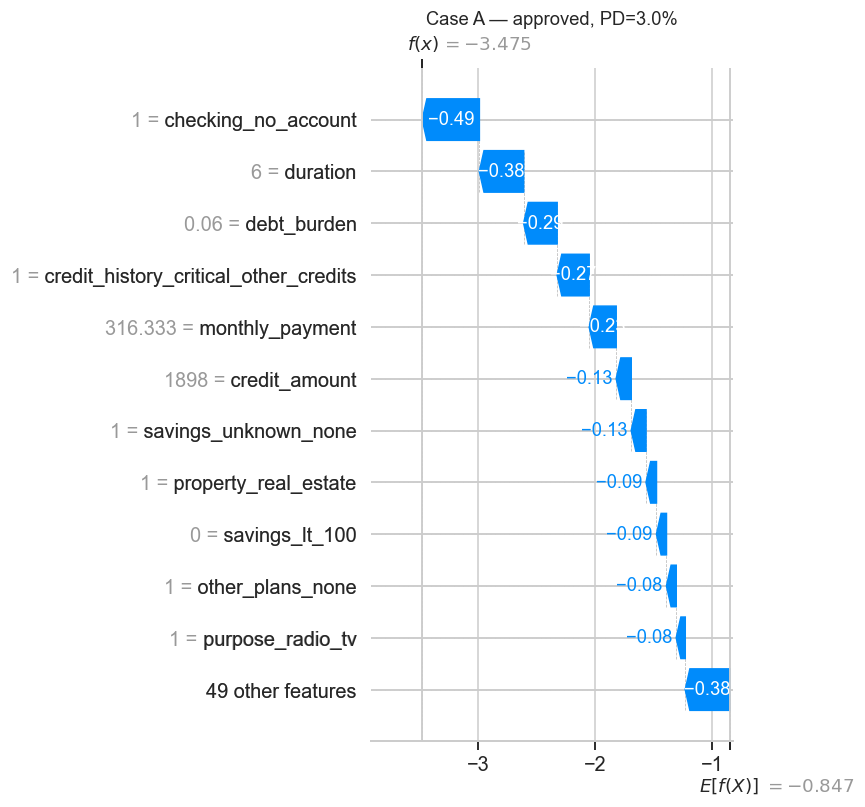

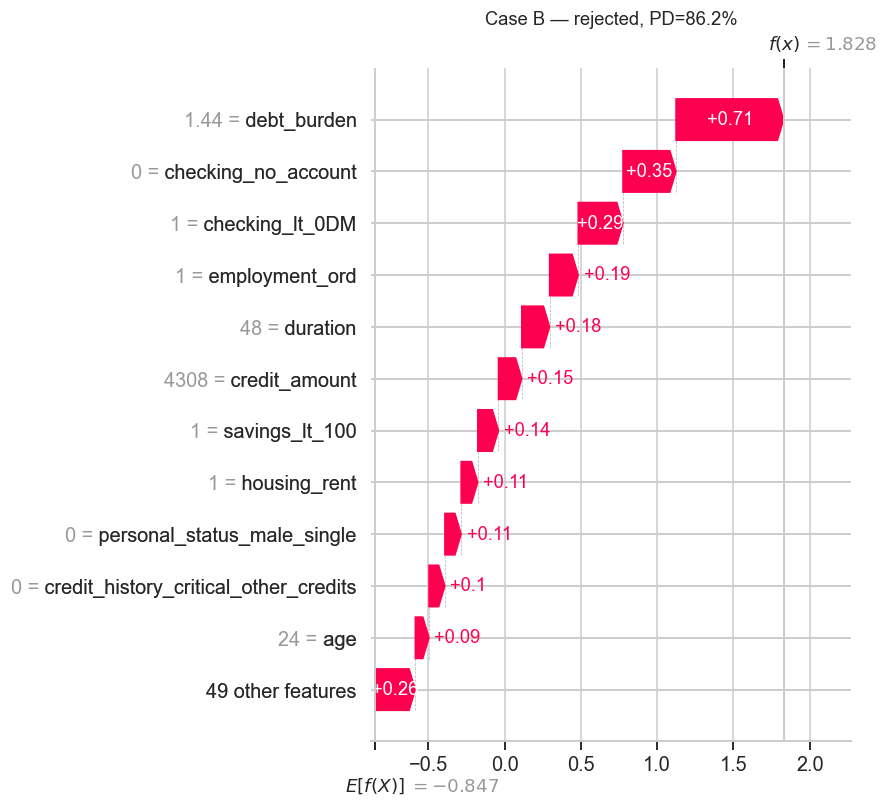

In [39]:
# مدل و آستانه‌ی نهایی
final_name = "XGBoost"
pd_final = p_test[final_name]
t_final = cutoffs[final_name]

# اتصال احتمال‌های پیش‌بینی‌شده به ردیف آزمون
probabilities = pd.Series(pd_final, index=X_test.index)

# مورد A: خوش‌حساب واقعی با کمترین احتمال نکول
idx_A = probabilities[y_test == 0].idxmin()

# مورد B: بدحساب واقعی با بیشترین احتمال نکول
idx_B = probabilities[y_test == 1].idxmax()

# تبدیل شناسه‌های ردیف به موقعیت موردنیاز برای دسترسی به مقادیر SHAP
iA = X_test.index.get_loc(idx_A)
iB = X_test.index.get_loc(idx_B)

# نمایش خلاصه‌ی دو پرونده
for label, position, row_index in [
    ("A (approved)", iA, idx_A),
    ("B (rejected)", iB, idx_B)
]:
    actual = "Bad" if y_test.loc[row_index] == 1 else "Good"
    print(
        f"Case {label}: PD={pd_final[position]:.3f} | "
        f"cut-off={t_final:.2f} | actual={actual}"
    )

# نمودار SHAP برای پرونده A
shap.plots.waterfall(shap_values[iA], max_display=12, show=False)
plt.title(f"Case A — approved, PD={pd_final[iA]:.1%}")
plt.tight_layout()
plt.savefig("figures/waterfall_A.png", bbox_inches="tight")
plt.show()

# نمودار SHAP برای پرونده B
shap.plots.waterfall(shap_values[iB], max_display=12, show=False)
plt.title(f"Case B — rejected, PD={pd_final[iB]:.1%}")
plt.tight_layout()
plt.savefig("figures/waterfall_B.png", bbox_inches="tight")
plt.show()

# نمودار Force تعاملی برای پرونده B
shap.initjs()
shap.force_plot(
    shap_values.base_values[iB],
    shap_values.values[iB],
    X_test_transformed.iloc[iB],
    matplotlib=False
)


<div dir="rtl" style="text-align: right">

### تحلیل موردی (Local) — دو پرونده از مجموعه‌ی آزمون

- **پرونده A:** خوش‌حساب واقعی با احتمال نکول پیش‌بینی‌شده‌ی حدود ۲٫۹٪؛ مدت بازپرداخت ۶ ماه و `debt_burden` برابر ۰٫۰۶ است. وضعیت حساب جاری این پرونده «بدون حساب جاری» ثبت شده است. نمودار Waterfall سهم ویژگی‌ها را در خروجی مدل برای این پرونده نشان می‌دهد.
- **پرونده B:** بدحساب واقعی با احتمال نکول پیش‌بینی‌شده‌ی حدود ۸۶٪؛ آستانه‌ی تصمیم ۰٫۱۹ است. مهم‌ترین سهم‌های مثبت SHAP در این پیش‌بینی عبارت‌اند از `debt_burden` (+۰٫۷۰)، حساب جاری منفی (+۰٫۳۰)، مدت وام ۴۸ماهه (+۰٫۲۰)، سابقه‌ی شغلی کمتر از یک سال (+۰٫۱۹)، مبلغ وام (+۰٫۱۶) و پس‌انداز کم (+۰٫۱۴).

مقادیر Waterfall در مقیاس **log-odds** هستند؛ بنابراین مستقیماً درصد احتمال نیستند. مجموع مقدار پایه و سهم‌های SHAP خروجی مدل را می‌سازد و تبدیل خروجی به احتمال با تابع سیگموید انجام می‌شود.

</div>


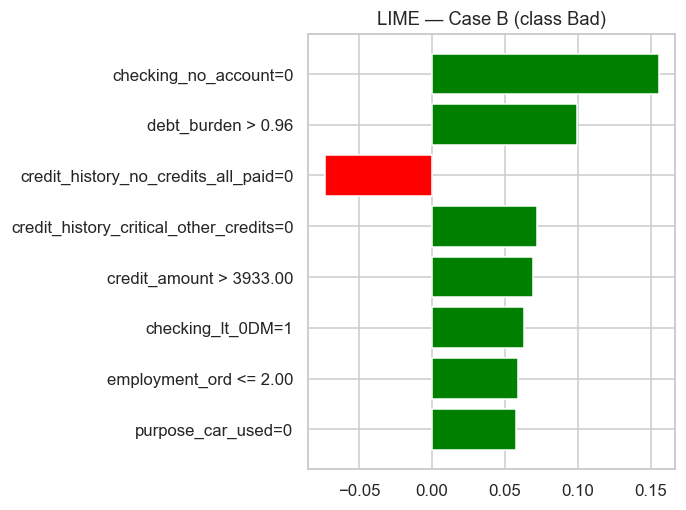

,SHAP (log-odds)
debt_burden,0.705
checking_no_account,0.347
checking_lt_0DM,0.293
employment_ord,0.187
duration,0.183
credit_amount,0.153
savings_lt_100,0.136
housing_rent,0.109


,LIME rule,LIME weight
0,checking_no_account=0,0.155
1,debt_burden > 0.96,0.100
2,credit_history_no_credits_all_paid=0,-0.074
3,credit_history_critical_other_credits=0,0.072
4,credit_amount > 3933.00,0.069
5,checking_lt_0DM=1,0.063
6,employment_ord <= 2.00,0.059
7,purpose_car_used=0,0.058


In [40]:
# تبدیل Train با همان پیش‌پردازشی که داخل Pipeline روی Train برازش شده
X_train_transformed = prep.transform(X_train_fe)

# مشخص‌کردن ستون‌های One-Hot برای LIME
categorical_idx = [
    i for i, column in enumerate(X_train_transformed.columns)
    if column not in num_cols_model
]

# ساخت توضیح‌گر LIME
lime_exp = LimeTabularExplainer(
    X_train_transformed.to_numpy(),
    feature_names=list(X_train_transformed.columns),
    class_names=["Good", "Bad"],
    categorical_features=categorical_idx,
    mode="classification",
    random_state=SEED,
    discretize_continuous=True
)

# توضیح پرونده‌ی B
exp = lime_exp.explain_instance(
    X_test_transformed.iloc[iB].to_numpy(),
    clf.predict_proba,
    num_features=8,
    num_samples=5000
)

# نمایش و ذخیره‌ی نمودار LIME
fig = exp.as_pyplot_figure()
plt.title("LIME — Case B (class Bad)")
plt.tight_layout()
plt.savefig("figures/lime_B.png", bbox_inches="tight")
plt.show()

# نمایش ۸ ویژگی با بیشترین قدرمطلق SHAP برای همان پرونده
shap_case = pd.Series(
    shap_values.values[iB],
    index=shap_values.feature_names
)
shap_top = shap_case.loc[
    shap_case.abs().sort_values(ascending=False).head(8).index
]

# نمایش ویژگی‌های LIME
lime_top = pd.DataFrame(
    exp.as_list(),
    columns=["LIME rule", "LIME weight"]
)

display(shap_top.round(3).rename("SHAP (log-odds)").to_frame())
display(lime_top.round(3))


<div dir="rtl" style="text-align: right">

### LIME در برابر SHAP برای پرونده B 
در میان هشت عامل برتر هر روش، پنج ویژگی مشترک‌اند: بااین‌حال، رتبه‌بندی و وزن‌های دو روش یکسان نیستند.
LIME یک تقریب خطی محلی روی همسایگی نمونه برداری شده است و به تعریف همسایگی و 
Sampling حساس است (اجرای مجدد ممکن است کمی فرق بدهد)؛ SHAP بر پای هی نظریه ی بازی ها پایدارتر و دارای Additivity دقیق است. نتیجه: برای پرونده های رسمی (Reason Codes) SHAP را ترجیح میدهیم و LIME را به عنوان Sanity Check به کار میبریم.
</div>


<div dir="rtl" style="text-align: right">

## ۵) (امتیازی) پرامپت LLM برای «دلایل رد درخواست» (Adverse Action)

**چالش:** مشتری و کارشناس شعبه، نمودار SHAP یا عدد log-odds را نمی‌فهمند.
**راه‌حل:** لایه‌ی «ترجمه‌ی SHAP به زبان مشتری» با این اصول:
1. **فیلتر قبل از LLM (در کد، نه در پرامپت):** ویژگی‌های حساس (`age`, `personal_status`, `foreign_worker`) هرگز به‌عنوان دلیل رد وارد پرامپت نمی‌شوند؛ ویژگی‌های خلاف‌شهود/غیرقابل‌اقدام (`checking_no_account` و `credit_history_critical`) نیز حذف می‌شوند.
2. فقط ۴ عامل برتر **افزایش‌دهنده‌ی ریسک** با شدت کیفی (زیاد/متوسط/کم) به LLM داده می‌شود، نه اعداد خام.
3. پرامپت ساختار، طول، لحن، ممنوعیت‌ها (اصطلاح فنی و اختراع دلیل) و وجود ۳ پیشنهاد عملی را مشخص می‌کند.
4. پیام نهایی باید قبل از ارسال، با `Reason Code` ذخیره‌شده در Log سازگار باشد (قابل‌ممیزی).

</div>

In [41]:
# ============================================================
# Adverse Action Prompt برای Case B
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display, Markdown


# ------------------------------------------------------------
# 1) بررسی وجود متغیرهای مورد نیاز
# ------------------------------------------------------------

required_variables = [
    "shap_values",
    "X_test_transformed",
    "X_test_fe",
    "iB",
    "idx_B",
]

missing_variables = [
    variable
    for variable in required_variables
    if variable not in globals()
]

if missing_variables:
    raise RuntimeError(
        "این متغیرها در محیط نوت‌بوک پیدا نشدند:\n"
        + ", ".join(missing_variables)
        + "\n\n"
        "این سلول باید بعد از سلول‌های مربوط به SHAP و Case B اجرا شود."
    )


# ------------------------------------------------------------
# 2) تنظیمات
# ------------------------------------------------------------

MAX_REASONS = 4
MAX_SUGGESTIONS = 3
MAX_WORDS = 150

# ویژگی‌های حساس که هرگز نباید به مشتری نمایش داده شوند
PROTECTED_PREFIXES = (
    "age",
    "personal_status",
    "foreign_worker",
    "sex",
    "gender",
    "nationality",
    "marital_status",
)

# ویژگی‌هایی که اجازه دارند به‌عنوان دلیل مشتری استفاده شوند
REASON_FEATURES = {
    "debt_burden",
    "duration",
    "credit_amount",
    "checking_lt_0DM",
    "savings_lt_100",
    "employment_ord",
    "stability_score",
}


# ------------------------------------------------------------
# 3) توابع کمکی
# ------------------------------------------------------------

def is_protected_feature(feature_name):
    """
    ویژگی‌های حساس و One-Hotهای مربوط به آن‌ها را شناسایی می‌کند.
    مثال:
    age
    personal_status_male_single
    foreign_worker_yes
    """
    return any(
        feature_name == prefix
        or feature_name.startswith(prefix + "_")
        for prefix in PROTECTED_PREFIXES
    )


def safe_number(value, decimals=0):
    try:
        if decimals == 0:
            return f"{float(value):,.0f}"
        return f"{float(value):,.{decimals}f}"
    except Exception:
        return "مقدار ثبت‌شده در پرونده"


def employment_label(value):
    labels = {
        0: "بیکار",
        1: "کمتر از ۱ سال",
        2: "۱ تا ۴ سال",
        3: "۴ تا ۷ سال",
        4: "۷ سال و بیشتر",
    }

    try:
        return labels.get(
            int(round(float(value))),
            "وضعیت ثبت‌شده در پرونده"
        )
    except Exception:
        return "وضعیت ثبت‌شده در پرونده"


def get_case_value(feature_name):
    """
    مقدار ویژگی را از محل مناسب در نوت‌بوک می‌خواند.

    ویژگی‌های مهندسی‌شده و عددی:
        X_test_fe

    ویژگی‌های One-Hot:
        X_test_transformed
    """

    # ابتدا ویژگی One-Hot را بررسی می‌کنیم
    if feature_name in X_test_transformed.columns:
        return X_test_transformed.iloc[iB][feature_name]

    # سپس ویژگی اصلی یا مهندسی‌شده را بررسی می‌کنیم
    if feature_name in X_test_fe.columns:
        return X_test_fe.iloc[iB][feature_name]

    return None


def make_reason_text(feature_name, value):
    """
    تبدیل نام ویژگی و مقدار آن به متن قابل‌فهم برای مشتری.
    """

    if feature_name == "debt_burden":
        return (
            "سهم بازپرداخت اقساط نسبت به درآمد نسبتاً بالا است",
            "بار بازپرداخت نسبت به درآمد بالاست",
        )

    if feature_name == "duration":
        return (
            "مدت بازپرداخت درخواستی نسبتاً طولانی است",
            f"{safe_number(value)} ماه",
        )

    if feature_name == "credit_amount":
        return (
            "مبلغ وام درخواستی نسبتاً بالا است",
            f"{safe_number(value)} واحد پول ثبت‌شده در پرونده",
        )

    if feature_name == "checking_lt_0DM":
        return (
            "حساب جاری در سابقه اخیر موجودی منفی داشته است",
            "موجودی منفی",
        )

    if feature_name == "savings_lt_100":
        return (
            "پس‌انداز نقدی ثبت‌شده پایین است",
            "کمتر از ۱۰۰ واحد پول ثبت‌شده",
        )

    if feature_name == "employment_ord":
        return (
            "سابقه اشتغال در شغل فعلی کوتاه است",
            employment_label(value),
        )

    if feature_name == "stability_score":
        return (
            "شاخص ثبات شغلی و سکونتی در این ارزیابی پایین‌تر است",
            f"امتیاز {safe_number(value)} از ۱۰",
        )

    return None


# ------------------------------------------------------------
# 4) استخراج مقدارهای SHAP مربوط به Case B
# ------------------------------------------------------------

if hasattr(shap_values, "feature_names") and shap_values.feature_names:
    shap_feature_names = list(shap_values.feature_names)
else:
    shap_feature_names = list(X_test_transformed.columns)

case_shap_array = np.asarray(
    shap_values.values[iB]
).reshape(-1)

if len(shap_feature_names) != len(case_shap_array):
    raise RuntimeError(
        "تعداد feature_names با تعداد مقادیر SHAP برابر نیست."
    )

case_shap = pd.Series(
    case_shap_array,
    index=shap_feature_names,
    dtype="float64"
)


# ------------------------------------------------------------
# 5) انتخاب دلایل قابل‌نمایش
# ------------------------------------------------------------

selected_reasons = []

# فقط عوامل مثبت؛ یعنی عواملی که خروجی مدل را به سمت ریسک بیشتر برده‌اند
positive_shap = (
    case_shap[case_shap > 0]
    .sort_values(ascending=False)
)

for feature_name, shap_value in positive_shap.items():

    feature_name = str(feature_name)

    # حذف ویژگی‌های حساس
    if is_protected_feature(feature_name):
        continue

    # فقط ویژگی‌های مشخص‌شده در سیاست کسب‌وکار
    if feature_name not in REASON_FEATURES:
        continue

    feature_value = get_case_value(feature_name)

    if feature_value is None:
        continue

    # One-Hotها فقط زمانی نمایش داده می‌شوند که فعال باشند
    if feature_name in {"checking_lt_0DM", "savings_lt_100"}:
        try:
            if float(feature_value) != 1:
                continue
        except Exception:
            continue

    reason_result = make_reason_text(
        feature_name,
        feature_value
    )

    if reason_result is None:
        continue

    reason_title, reason_value = reason_result

    selected_reasons.append({
        "feature": feature_name,
        "title": reason_title,
        "value": reason_value,
        "shap_value": float(shap_value),
    })

    if len(selected_reasons) >= MAX_REASONS:
        break


# ------------------------------------------------------------
# 6) متن دلایل برای قرارگرفتن در پرامپت
# ------------------------------------------------------------

if selected_reasons:
    reasons_for_prompt = "\n".join(
        f"- {item['title']}؛ وضعیت ثبت‌شده: {item['value']}"
        for item in selected_reasons
    )
else:
    reasons_for_prompt = (
        "- دلیل قابل‌نمایش و قابل‌اقدام کافی در این ارزیابی ثبت نشده است."
    )


# ------------------------------------------------------------
# 7) تنظیم بررسی انسانی
# ------------------------------------------------------------

HUMAN_REVIEW_AVAILABLE = True

if HUMAN_REVIEW_AVAILABLE:
    HUMAN_REVIEW_TEXT = (
        "در صورت تمایل، می‌توانید از طریق شعبه یا پشتیبانی بانک "
        "درخواست بررسی انسانی پرونده را مطرح کنید."
    )
else:
    HUMAN_REVIEW_TEXT = (
        "امکان بررسی انسانی برای این پرونده تأیید نشده است."
    )


# ------------------------------------------------------------
# 8) ساخت پرامپت نهایی برای LLM
# ------------------------------------------------------------

customer_message_prompt = f"""
شما یک کارشناس ارتباط با مشتری در یک بانک هستید.

درخواست تسهیلات مشتری در ارزیابی فعلی تأیید نشده است. یک پیام کوتاه،
شفاف، محترمانه و کمک‌کننده به زبان فارسی روان برای مشتری بنویسید.

هدف پیام:
۱. مشتری نتیجه را بدون ابهام بفهمد؛
۲. عوامل قابل‌فهم مؤثر در ارزیابی را بشناسد؛
۳. برای بهبود شرایط، چند قدم عملی و واقع‌بینانه داشته باشد؛
۴. در صورت وجود، از امکان بررسی انسانی پرونده مطلع شود.

قوانین قطعی:
- حداکثر {MAX_WORDS} کلمه بنویس.
- لحن همدلانه، رسمی، ساده و غیرسرزنشگر باشد.
- پیام را با سلام و بیان روشن نتیجه آغاز کن.
- توضیح بده که رد شدن درخواست به معنای قضاوت درباره شخصیت یا ارزش مشتری نیست.
- فقط از دلایل فهرست‌شده در اطلاعات پرونده استفاده کن.
- هیچ دلیل جدیدی حدس نزن.
- به سن، جنسیت، وضعیت تأهل، ملیت، خارجی‌بودن یا هر ویژگی حساس دیگری اشاره نکن.
- از واژه‌های مدل، الگوریتم، SHAP، امتیاز ریسک و احتمال نکول استفاده نکن.
- دلایل را به همان ترتیب ارائه‌شده بیان کن.
- درباره شدت اثر، از عبارت‌های زیاد، متوسط یا کم استفاده نکن.
- حداکثر {MAX_SUGGESTIONS} پیشنهاد عملی برای ۳ تا ۶ ماه آینده ارائه کن.
- هر پیشنهاد باید مستقیماً به یکی از دلایل فهرست‌شده مربوط باشد.
- اگر برای یک پیشنهاد اطلاعات کافی وجود ندارد، آن را نساز.
- تأیید قطعی درخواست بعدی را وعده نده.
- در پایان بگو مشتری می‌تواند پس از بهبود شرایط دوباره درخواست دهد.
- درباره بررسی انسانی فقط بر اساس اطلاعاتی که در ادامه آمده بنویس.
- فقط متن نهایی خطاب به مشتری را بنویس.

ساختار پیام:
سلام و نتیجه روشن
دلایل اصلی به زبان ساده
پیشنهادهای عملی برای گام بعدی
جمله پایانی محترمانه و امیدوارکننده اما غیرقطعی

دلایل پرونده:
{reasons_for_prompt}

امکان بررسی انسانی:
{"فعال است" if HUMAN_REVIEW_AVAILABLE else "فعال نیست"}

اطلاعات مربوط به بررسی انسانی:
{HUMAN_REVIEW_TEXT}
""".strip()


# ------------------------------------------------------------
# 9) ساخت پیشنهادهای عملی برای نمونه خروجی
# ------------------------------------------------------------

selected_features = {
    item["feature"]
    for item in selected_reasons
}

suggestions = []

if (
    "duration" in selected_features
    or "credit_amount" in selected_features
):
    suggestions.append(
        "درخواست بعدی را با مبلغ یا مدت بازپرداخت پایین‌تری بررسی کنید."
    )

if "debt_burden" in selected_features:
    suggestions.append(
        "در چند ماه آینده، نسبت تعهدات بازپرداختی به درآمد خود را کاهش دهید."
    )

if "employment_ord" in selected_features:
    suggestions.append(
        "پس از ایجاد سابقه اشتغال طولانی‌تر، شرایط درخواست بعدی را بررسی کنید."
    )

if "checking_lt_0DM" in selected_features:
    suggestions.append(
        "وضعیت حساب جاری و موجودی منفی را در ماه‌های آینده منظم‌تر کنید."
    )

if "savings_lt_100" in selected_features:
    suggestions.append(
        "در صورت امکان، پس‌انداز نقدی خود را افزایش دهید."
    )

if not suggestions:
    suggestions.append(
        "پس از بررسی شرایط مالی و تکمیل اطلاعات پرونده، "
        "برای درخواست بعدی اقدام کنید."
    )

suggestions = suggestions[:MAX_SUGGESTIONS]


# ------------------------------------------------------------
# 10) ساخت نمونه خروجی متنی بدون نیاز به API
# ------------------------------------------------------------

if selected_reasons:
    customer_reason_lines = "\n".join(
        f"- {item['title']} ({item['value']})"
        for item in selected_reasons
    )
else:
    customer_reason_lines = (
        "- دلیل قابل‌نمایش کافی برای ارائه به مشتری ثبت نشده است."
    )

customer_suggestion_lines = "\n".join(
    f"- {suggestion}"
    for suggestion in suggestions
)

human_review_customer_text = (
    f"\n\n{HUMAN_REVIEW_TEXT}"
    if HUMAN_REVIEW_AVAILABLE
    else ""
)

customer_message_draft = f"""
سلام،

درخواست تسهیلات شما در ارزیابی فعلی تأیید نشد. این نتیجه به معنای قضاوت درباره شخصیت یا ارزش شما نیست و به شرایط ثبت‌شده در همین درخواست مربوط می‌شود.

مواردی که در ارزیابی نقش داشتند:
{customer_reason_lines}

برای آماده‌تر شدن برای درخواست بعدی، می‌توانید:
{customer_suggestion_lines}

پس از بهبود شرایط می‌توانید دوباره درخواست دهید.
{human_review_customer_text}

با احترام
""".strip()


# ------------------------------------------------------------
# 11) نمایش نتایج
# ------------------------------------------------------------

print("=" * 70)
print("دلایل انتخاب‌شده برای Case B")
print("=" * 70)

if selected_reasons:
    for item in selected_reasons:
        print(
            f"- {item['feature']} | "
            f"SHAP={item['shap_value']:.4f} | "
            f"{item['title']} | "
            f"{item['value']}"
        )
else:
    print("هیچ دلیل قابل‌نمایش و قابل‌اقدامی انتخاب نشد.")

display(Markdown("## پرامپت نهایی برای مدل زبانی"))
print(customer_message_prompt)

display(Markdown("## نمونه خروجی نهایی خطاب به مشتری"))
print(customer_message_draft)



دلایل انتخاب‌شده برای Case B
- debt_burden | SHAP=0.7050 | سهم بازپرداخت اقساط نسبت به درآمد نسبتاً بالا است | بار بازپرداخت نسبت به درآمد بالاست
- checking_lt_0DM | SHAP=0.2931 | حساب جاری در سابقه اخیر موجودی منفی داشته است | موجودی منفی
- employment_ord | SHAP=0.1873 | سابقه اشتغال در شغل فعلی کوتاه است | کمتر از ۱ سال
- duration | SHAP=0.1826 | مدت بازپرداخت درخواستی نسبتاً طولانی است | 48 ماه


## پرامپت نهایی برای مدل زبانی

شما یک کارشناس ارتباط با مشتری در یک بانک هستید.

درخواست تسهیلات مشتری در ارزیابی فعلی تأیید نشده است. یک پیام کوتاه،
شفاف، محترمانه و کمک‌کننده به زبان فارسی روان برای مشتری بنویسید.

هدف پیام:
۱. مشتری نتیجه را بدون ابهام بفهمد؛
۲. عوامل قابل‌فهم مؤثر در ارزیابی را بشناسد؛
۳. برای بهبود شرایط، چند قدم عملی و واقع‌بینانه داشته باشد؛
۴. در صورت وجود، از امکان بررسی انسانی پرونده مطلع شود.

قوانین قطعی:
- حداکثر 150 کلمه بنویس.
- لحن همدلانه، رسمی، ساده و غیرسرزنشگر باشد.
- پیام را با سلام و بیان روشن نتیجه آغاز کن.
- توضیح بده که رد شدن درخواست به معنای قضاوت درباره شخصیت یا ارزش مشتری نیست.
- فقط از دلایل فهرست‌شده در اطلاعات پرونده استفاده کن.
- هیچ دلیل جدیدی حدس نزن.
- به سن، جنسیت، وضعیت تأهل، ملیت، خارجی‌بودن یا هر ویژگی حساس دیگری اشاره نکن.
- از واژه‌های مدل، الگوریتم، SHAP، امتیاز ریسک و احتمال نکول استفاده نکن.
- دلایل را به همان ترتیب ارائه‌شده بیان کن.
- درباره شدت اثر، از عبارت‌های زیاد، متوسط یا کم استفاده نکن.
- حداکثر 3 پیشنهاد عملی برای ۳ تا ۶ ماه آینده ارائه کن.
- هر

## نمونه خروجی نهایی خطاب به مشتری

سلام،

درخواست تسهیلات شما در ارزیابی فعلی تأیید نشد. این نتیجه به معنای قضاوت درباره شخصیت یا ارزش شما نیست و به شرایط ثبت‌شده در همین درخواست مربوط می‌شود.

مواردی که در ارزیابی نقش داشتند:
- سهم بازپرداخت اقساط نسبت به درآمد نسبتاً بالا است (بار بازپرداخت نسبت به درآمد بالاست)
- حساب جاری در سابقه اخیر موجودی منفی داشته است (موجودی منفی)
- سابقه اشتغال در شغل فعلی کوتاه است (کمتر از ۱ سال)
- مدت بازپرداخت درخواستی نسبتاً طولانی است (48 ماه)

برای آماده‌تر شدن برای درخواست بعدی، می‌توانید:
- درخواست بعدی را با مبلغ یا مدت بازپرداخت پایین‌تری بررسی کنید.
- در چند ماه آینده، نسبت تعهدات بازپرداختی به درآمد خود را کاهش دهید.
- پس از ایجاد سابقه اشتغال طولانی‌تر، شرایط درخواست بعدی را بررسی کنید.

پس از بهبود شرایط می‌توانید دوباره درخواست دهید.


در صورت تمایل، می‌توانید از طریق شعبه یا پشتیبانی بانک درخواست بررسی انسانی پرونده را مطرح کنید.

با احترام
